In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

# 挤出力曲线作图

In [3]:
file_path1 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\SU311\2026.9.10挤出力曲线测试\20260910_091058_SU311-1 220℃_stats_clip3.0s.csv"
file_path2 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\SU311\2026.9.10挤出力曲线测试\20260910_095346_SU311-2 220℃_stats_clip3.0s.csv"
data1 = pd.read_csv(file_path1)
data2 = pd.read_csv(file_path2)

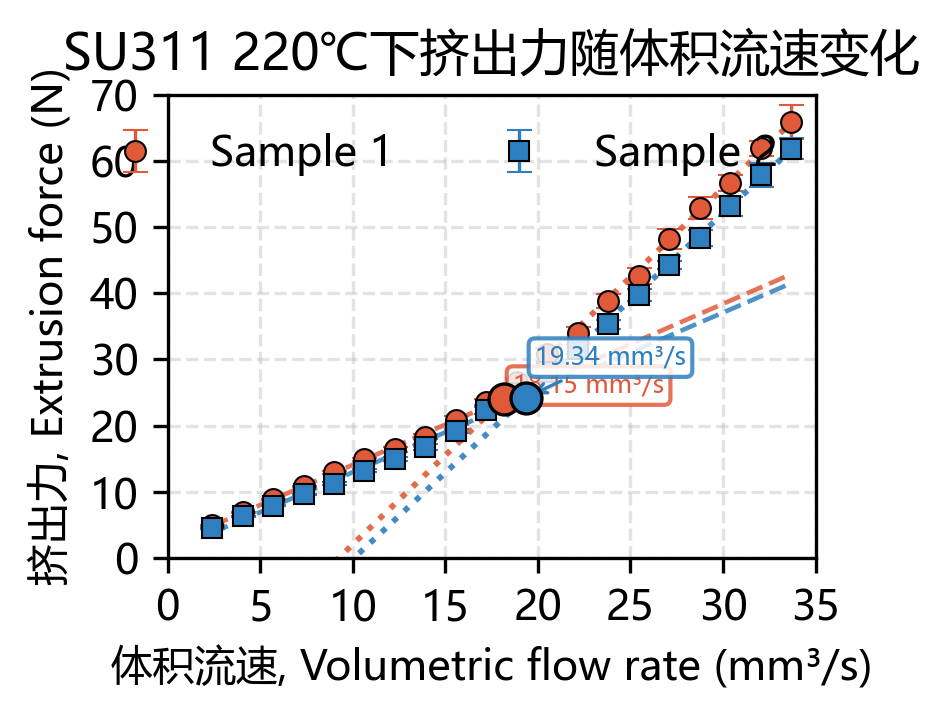


拐点计算结果：
         样品  拐点体积流速 mm³/s    拐点挤出力 N    低流速段斜率    低流速段截距    高流速段斜率     高流速段截距
0  Sample 1     18.151725  23.995424  1.217492  1.895841  2.694948 -24.922530
1  Sample 2     19.339655  24.224379  1.207052  0.880407  2.614933 -26.347519


In [7]:
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

# =========================
# 2. 数据整理函数
# =========================
def prepare_data(df):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip()
    # 转换为数值
    df["feedrate_mms"] = pd.to_numeric(df["feedrate_mms"], errors="coerce")
    df["extrusion_force_N_mean"] = pd.to_numeric(df["extrusion_force_N_mean"], errors="coerce")
    df["extrusion_force_N_std"] = pd.to_numeric(df["extrusion_force_N_std"], errors="coerce")
    # 体积流速 = feedrate_mms × π × 0.875²
    df["volume_flow_mm3_s"] = df["feedrate_mms"] * np.pi * 0.875**2
    # 去除无效数据
    df = df.dropna(subset=[
        "volume_flow_mm3_s",
        "extrusion_force_N_mean",
        "extrusion_force_N_std"
    ]).copy()

    # 按体积流速排序
    df = df.sort_values("volume_flow_mm3_s").reset_index(drop=True)

    return df


# =========================
# 3. 双线性拟合函数：用两条直线交点作为拐点
# =========================
def find_breakpoint_by_two_lines(x, y, min_points=4):
    """
    双线性拟合寻找拐点：
    遍历所有可能分割点，分别拟合低流速段和高流速段，
    选择总残差最小的分割点。
    两条直线的交点作为拐点。
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # 按 x 排序
    idx = np.argsort(x)
    x = x[idx]
    y = y[idx]

    best = None

    for split in range(min_points, len(x) - min_points + 1):
        x1, y1 = x[:split], y[:split]
        x2, y2 = x[split:], y[split:]

        # 左右两段分别线性拟合
        k1, b1 = np.polyfit(x1, y1, 1)
        k2, b2 = np.polyfit(x2, y2, 1)

        y1_fit = k1 * x1 + b1
        y2_fit = k2 * x2 + b2

        sse = np.sum((y1 - y1_fit) ** 2) + np.sum((y2 - y2_fit) ** 2)

        if best is None or sse < best["sse"]:
            best = {
                "split": split,
                "k1": k1,
                "b1": b1,
                "k2": k2,
                "b2": b2,
                "sse": sse
            }

    k1, b1 = best["k1"], best["b1"]
    k2, b2 = best["k2"], best["b2"]

    # 两条直线交点
    if abs(k1 - k2) < 1e-12:
        x_cross = np.nan
        y_cross = np.nan
    else:
        x_cross = (b2 - b1) / (k1 - k2)
        y_cross = k1 * x_cross + b1

    best["x_cross"] = x_cross
    best["y_cross"] = y_cross

    return best


# =========================
# 4. 设置两个样品名称
# =========================
datasets = [
    {
        "df": data1,
        "label": "Sample 1",
        "color": "#E05A3A",
        "marker": "o",
        "text_offset": (3,1) 
    },
    {
        "df": data2,
        "label": "Sample 2",
        "color": "#2E7FBF",
        "marker": "s",
        "text_offset": (5, 5.0) 
    }
]


# =========================
# 5. 作图
# =========================
fig, ax = plt.subplots(figsize=(3, 2.5), dpi=300)

results = []

for item in datasets:
    df = prepare_data(item["df"])

    label = item["label"]
    color = item["color"]
    marker = item["marker"]

    x = df["volume_flow_mm3_s"].values
    y = df["extrusion_force_N_mean"].values
    yerr = df["extrusion_force_N_std"].values

    # 散点 + 标准差误差棒
    ax.errorbar(
        x,
        y,
        yerr=yerr,
        fmt=marker,
        color=color,
        markersize=5,
        capsize=3,
        linewidth=0,
        elinewidth=0.8,
        markeredgecolor="black",
        markeredgewidth=0.5,
        label=f"{label}"
    )

    # 双线性拟合
    fit = find_breakpoint_by_two_lines(x, y, min_points=4)

    k1, b1 = fit["k1"], fit["b1"]
    k2, b2 = fit["k2"], fit["b2"]
    x_cross = fit["x_cross"]
    y_cross = fit["y_cross"]

    # 画两条拟合直线
    x_fit = np.linspace(x.min(), x.max(), 300)
    y_fit1 = k1 * x_fit + b1
    y_fit2 = k2 * x_fit + b2

    ax.plot(
        x_fit,
        y_fit1,
        linestyle="--",
        color=color,
        linewidth=1.1,
        alpha=0.85,
    )

    ax.plot(
        x_fit,
        y_fit2,
        linestyle=":",
        color=color,
        linewidth=1.4,
        alpha=0.9,
    )

    # 标出拐点
    ax.scatter(
        x_cross,
        y_cross,
        s=55,
        color=color,
        edgecolors="black",
        linewidths=0.8,
        zorder=5
    )

    dx, dy = item["text_offset"]
    ax.annotate(
        f"{x_cross:.2f} mm³/s",
        xy=(x_cross, y_cross),
        xytext=(x_cross + 0.5, y_cross + dy),
        fontsize=6,
        color=color,
        arrowprops=dict(
            arrowstyle="->",
            color=color,
            lw=0.8
        ),
        bbox=dict(
            boxstyle="round,pad=0.25",
            fc="white",
            ec=color,
            alpha=0.85
        )
    )

    results.append({
        "样品": label,
        "拐点体积流速 mm³/s": x_cross,
        "拐点挤出力 N": y_cross,
        "低流速段斜率": k1,
        "低流速段截距": b1,
        "高流速段斜率": k2,
        "高流速段截距": b2
    })


# =========================
# 6. 图形格式
# =========================
ax.set_xlabel("体积流速, Volumetric flow rate (mm³/s)")
ax.set_ylabel("挤出力, Extrusion force (N)")
ax.set_title("SU311 220℃下挤出力随体积流速变化")
ax.grid(True, linestyle="--", alpha=0.35)
ax.set_xlim(0, 35)
ax.set_ylim(0, 70)
ax.xaxis.set_major_locator(mticker.MaxNLocator(8))
ax.yaxis.set_major_locator(mticker.MaxNLocator(8))

ax.legend(frameon=False, ncol=2)

plt.tight_layout()
plt.show()


# =========================
# 7. 输出拐点结果
# =========================
result_df = pd.DataFrame(results)

print("\n拐点计算结果：")
print(result_df)

In [77]:
file_path1 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\U0390A\U0390AU挤出力测试\20260904_152101_U0390AU-2 225℃_stats_clip19.9s.csv"
data1 = pd.read_csv(file_path1)

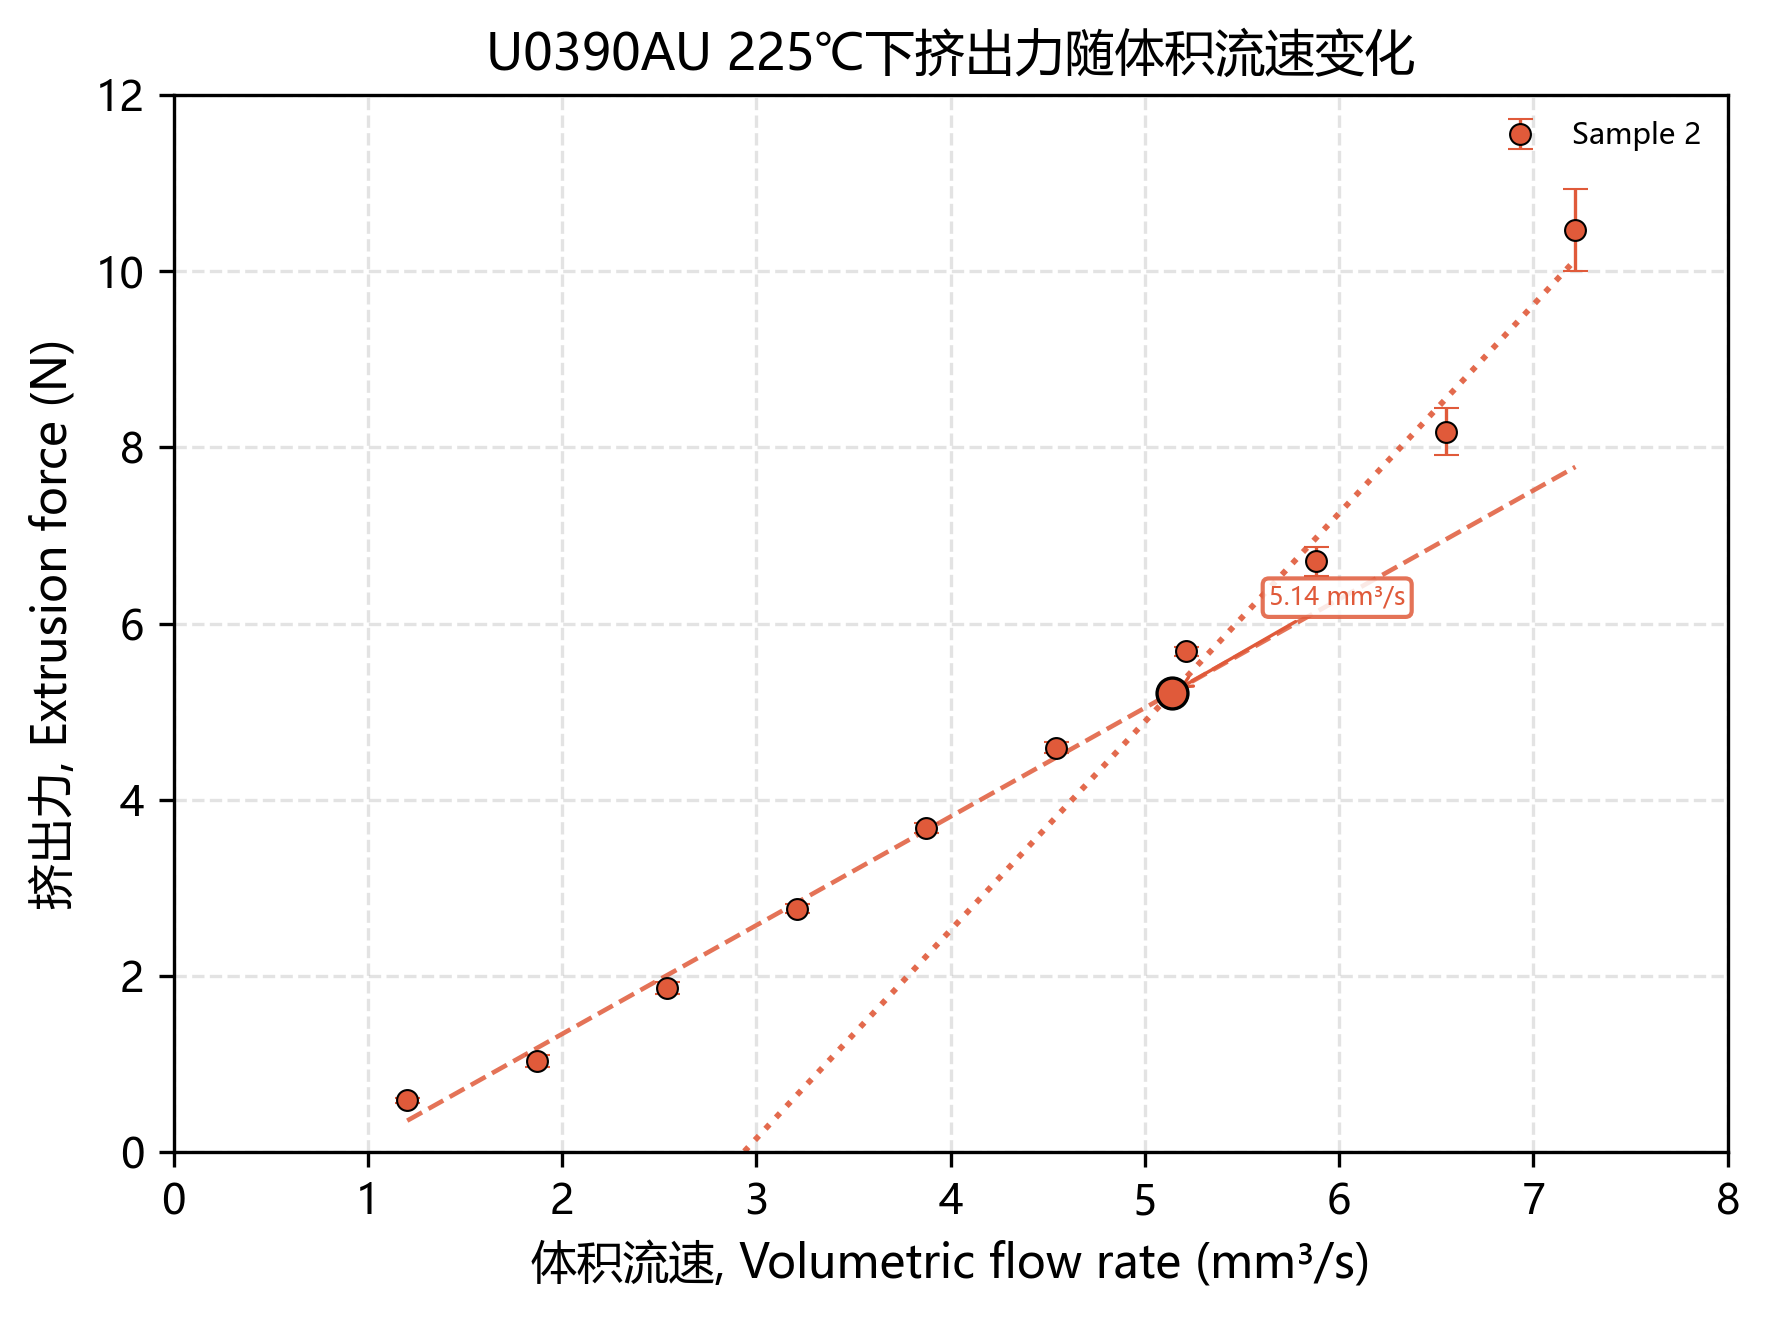


拐点计算结果：
         样品  拐点体积流速 mm³/s   拐点挤出力 N    低流速段斜率    低流速段截距    高流速段斜率    高流速段截距
0  Sample 2      5.138325  5.214728  1.234101 -1.126484  2.366033 -6.942717


In [79]:
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

# =========================
# 2. 数据整理函数
# =========================
def prepare_data(df):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip()
    # 转换为数值
    df["feedrate_mms"] = pd.to_numeric(df["feedrate_mms"], errors="coerce")
    df["extrusion_force_N_mean"] = pd.to_numeric(df["extrusion_force_N_mean"], errors="coerce")
    df["extrusion_force_N_std"] = pd.to_numeric(df["extrusion_force_N_std"], errors="coerce")
    # 体积流速 = feedrate_mms × π × 0.875²
    df["volume_flow_mm3_s"] = df["feedrate_mms"] * np.pi * 0.875**2
    # 去除无效数据
    df = df.dropna(subset=[
        "volume_flow_mm3_s",
        "extrusion_force_N_mean",
        "extrusion_force_N_std"
    ]).copy()

    # 按体积流速排序
    df = df.sort_values("volume_flow_mm3_s").reset_index(drop=True)

    return df


# =========================
# 3. 双线性拟合函数：用两条直线交点作为拐点
# =========================
def find_breakpoint_by_two_lines(x, y, min_points=4):
    """
    双线性拟合寻找拐点：
    遍历所有可能分割点，分别拟合低流速段和高流速段，
    选择总残差最小的分割点。
    两条直线的交点作为拐点。
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # 按 x 排序
    idx = np.argsort(x)
    x = x[idx]
    y = y[idx]

    best = None

    for split in range(min_points, len(x) - min_points + 1):
        x1, y1 = x[:split], y[:split]
        x2, y2 = x[split:], y[split:]

        # 左右两段分别线性拟合
        k1, b1 = np.polyfit(x1, y1, 1)
        k2, b2 = np.polyfit(x2, y2, 1)

        y1_fit = k1 * x1 + b1
        y2_fit = k2 * x2 + b2

        sse = np.sum((y1 - y1_fit) ** 2) + np.sum((y2 - y2_fit) ** 2)

        if best is None or sse < best["sse"]:
            best = {
                "split": split,
                "k1": k1,
                "b1": b1,
                "k2": k2,
                "b2": b2,
                "sse": sse
            }

    k1, b1 = best["k1"], best["b1"]
    k2, b2 = best["k2"], best["b2"]

    # 两条直线交点
    if abs(k1 - k2) < 1e-12:
        x_cross = np.nan
        y_cross = np.nan
    else:
        x_cross = (b2 - b1) / (k1 - k2)
        y_cross = k1 * x_cross + b1

    best["x_cross"] = x_cross
    best["y_cross"] = y_cross

    return best


# =========================
# 4. 设置两个样品名称
# =========================
datasets = [
    {
        "df": data1,
        "label": "Sample 2",
        "color": "#E05A3A",
        "marker": "o",
        "text_offset": (3,1) 
    }
]


# =========================
# 5. 作图
# =========================
fig, ax = plt.subplots(figsize=(6, 4.5), dpi=300)

results = []

for item in datasets:
    df = prepare_data(item["df"])

    label = item["label"]
    color = item["color"]
    marker = item["marker"]

    x = df["volume_flow_mm3_s"].values
    y = df["extrusion_force_N_mean"].values
    yerr = df["extrusion_force_N_std"].values

    # 散点 + 标准差误差棒
    ax.errorbar(
        x,
        y,
        yerr=yerr,
        fmt=marker,
        color=color,
        markersize=5,
        capsize=3,
        linewidth=0,
        elinewidth=0.8,
        markeredgecolor="black",
        markeredgewidth=0.5,
        label=f"{label}"
    )

    # 双线性拟合
    fit = find_breakpoint_by_two_lines(x, y, min_points=4)

    k1, b1 = fit["k1"], fit["b1"]
    k2, b2 = fit["k2"], fit["b2"]
    x_cross = fit["x_cross"]
    y_cross = fit["y_cross"]

    # 画两条拟合直线
    x_fit = np.linspace(x.min(), x.max(), 300)
    y_fit1 = k1 * x_fit + b1
    y_fit2 = k2 * x_fit + b2

    ax.plot(
        x_fit,
        y_fit1,
        linestyle="--",
        color=color,
        linewidth=1.1,
        alpha=0.85,
    )

    ax.plot(
        x_fit,
        y_fit2,
        linestyle=":",
        color=color,
        linewidth=1.4,
        alpha=0.9,
    )

    # 标出拐点
    ax.scatter(
        x_cross,
        y_cross,
        s=55,
        color=color,
        edgecolors="black",
        linewidths=0.8,
        zorder=5
    )

    dx, dy = item["text_offset"]
    ax.annotate(
        f"{x_cross:.2f} mm³/s",
        xy=(x_cross, y_cross),
        xytext=(x_cross + 0.5, y_cross + dy),
        fontsize=6,
        color=color,
        arrowprops=dict(
            arrowstyle="->",
            color=color,
            lw=0.8
        ),
        bbox=dict(
            boxstyle="round,pad=0.25",
            fc="white",
            ec=color,
            alpha=0.85
        )
    )

    results.append({
        "样品": label,
        "拐点体积流速 mm³/s": x_cross,
        "拐点挤出力 N": y_cross,
        "低流速段斜率": k1,
        "低流速段截距": b1,
        "高流速段斜率": k2,
        "高流速段截距": b2
    })


# =========================
# 6. 图形格式
# =========================
ax.set_xlabel("体积流速, Volumetric flow rate (mm³/s)", fontsize=11)
ax.set_ylabel("挤出力, Extrusion force (N)", fontsize=11)
ax.set_title("U0390AU 225℃下挤出力随体积流速变化", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.35)
ax.set_xlim(0, 8)
ax.set_ylim(0, 12)
ax.xaxis.set_major_locator(mticker.MaxNLocator(9))
ax.yaxis.set_major_locator(mticker.MaxNLocator(7))

ax.legend(fontsize=7, frameon=False, ncol=2)

plt.tight_layout()
plt.show()


# =========================
# 7. 输出拐点结果
# =========================
result_df = pd.DataFrame(results)

print("\n拐点计算结果：")
print(result_df)

In [3]:
file_path1 = r"C:\Users\Administrator\Desktop\挤出平台\争议样品复测\L3002\26.10.22\20261022_164444_L3002 51102_stats_clip3.0s.csv"
file_path2 = r"C:\Users\Administrator\Desktop\挤出平台\争议样品复测\L3002\26.10.22\20261022_171001_L3002 30623_stats_clip3.0s.csv"
file_path3 = r"C:\Users\Administrator\Desktop\挤出平台\争议样品复测\L3002\26.10.22\20261022_172456_L3002 27097_stats_clip3.0s.csv"
file_path4 = r"C:\Users\Administrator\Desktop\挤出平台\争议样品复测\L3002\26.10.22\20261023_091647_L3002 46900_stats_clip3.0s.csv"
#file_path5 = r"C:\Users\Administrator\Desktop\挤出平台\争议样品复测\L1013\L1013争议样品复测\20260930_160209_L1013 36052 220℃_stats_clip3.0s.csv"
data1 = pd.read_csv(file_path1)
data2 = pd.read_csv(file_path2)
data3 = pd.read_csv(file_path3)
data4 = pd.read_csv(file_path4)
#data5 = pd.read_csv(file_path5)

Empty DataFrame
Columns: []
Index: []


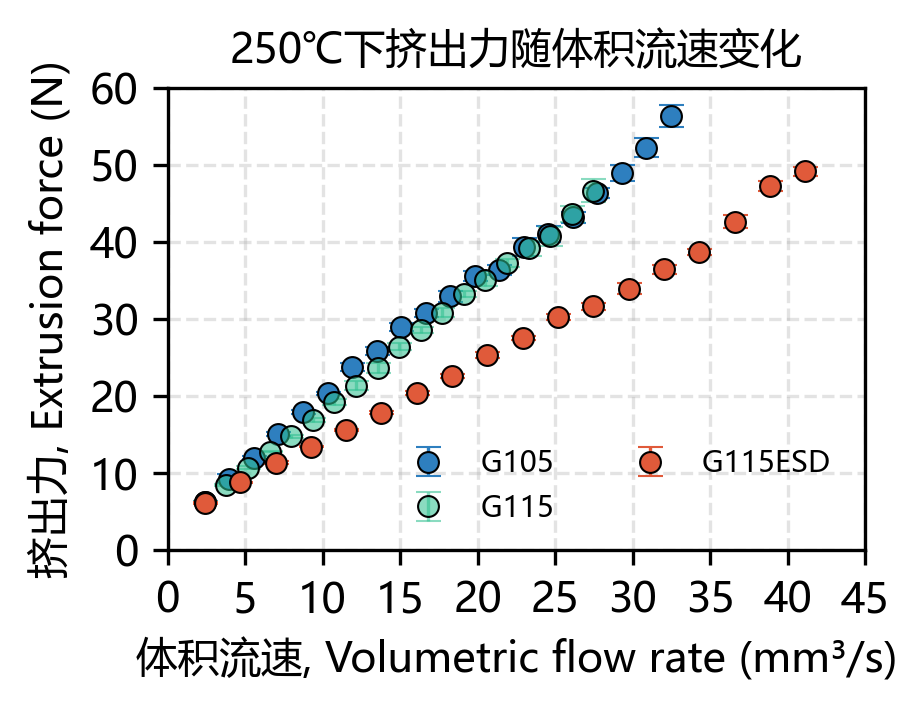

In [9]:
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
# =========================
# 2. 数据整理函数
# =========================
def prepare_data(df):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip()

    # 转换为数值
    df["feedrate_mms"] = pd.to_numeric(df["feedrate_mms"], errors="coerce")
    df["extrusion_force_N_mean"] = pd.to_numeric(df["extrusion_force_N_mean"], errors="coerce")
    df["extrusion_force_N_std"] = pd.to_numeric(df["extrusion_force_N_std"], errors="coerce")

    # 体积流速 = feedrate_mms × π × 0.875²
    df["volume_flow_mm3_s"] = df["feedrate_mms"] * np.pi * 0.875**2

    # 去除无效数据
    df = df.dropna(subset=[
        "volume_flow_mm3_s",
        "extrusion_force_N_mean",
        "extrusion_force_N_std"
    ]).copy()

    # 按体积流速排序
    df = df.sort_values("volume_flow_mm3_s").reset_index(drop=True)

    return df


# =========================
# 4. 设置两个样品名称
# =========================
datasets = [
    {
        "df": data1,
        "label": "G105",
        "color": "#2E7FBF",
        "marker": "o"
    },
    {
        "df": data2,
        "label": "G115",
        "color": "#2EBF8F8F",
        "marker": "o"
    },
    {
        "df": data3,
        "label": "G115ESD",
        "color": "#E05A3A",
        "marker": "o"
    }
]


# =========================
# 5. 作图
# =========================
fig, ax = plt.subplots(figsize=(3, 2), dpi=300)

results = []

for item in datasets:
    df = prepare_data(item["df"])

    label = item["label"]
    color = item["color"]
    marker = item["marker"]

    x = df["volume_flow_mm3_s"].values
    y = df["extrusion_force_N_mean"].values
    yerr = df["extrusion_force_N_std"].values

    # 散点 + 标准差误差棒
    ax.errorbar(
        x,
        y,
        yerr=yerr,
        fmt=marker,
        color=color,
        markersize=5,
        capsize=3,
        linewidth=0,
        elinewidth=0.8,
        markeredgecolor="black",
        markeredgewidth=0.5,
        label=f"{label} "
    )

   


# =========================
# 6. 图形格式
# =========================
ax.set_xlabel("体积流速, Volumetric flow rate (mm³/s)", fontsize=10)
ax.set_ylabel("挤出力, Extrusion force (N)", fontsize=10)
ax.set_title("250℃下挤出力随体积流速变化", fontsize=10)

ax.grid(True, linestyle="--", alpha=0.35)
ax.set_xlim(0, 45)
ax.set_ylim(0, 60)
ax.xaxis.set_major_locator(mticker.MaxNLocator(10))
ax.yaxis.set_major_locator(mticker.MaxNLocator(7))

ax.legend(fontsize=7, frameon=False, ncol=2)


# =========================
# 7. 输出拐点结果
# =========================
result_df = pd.DataFrame(results)
print(result_df)

Empty DataFrame
Columns: []
Index: []


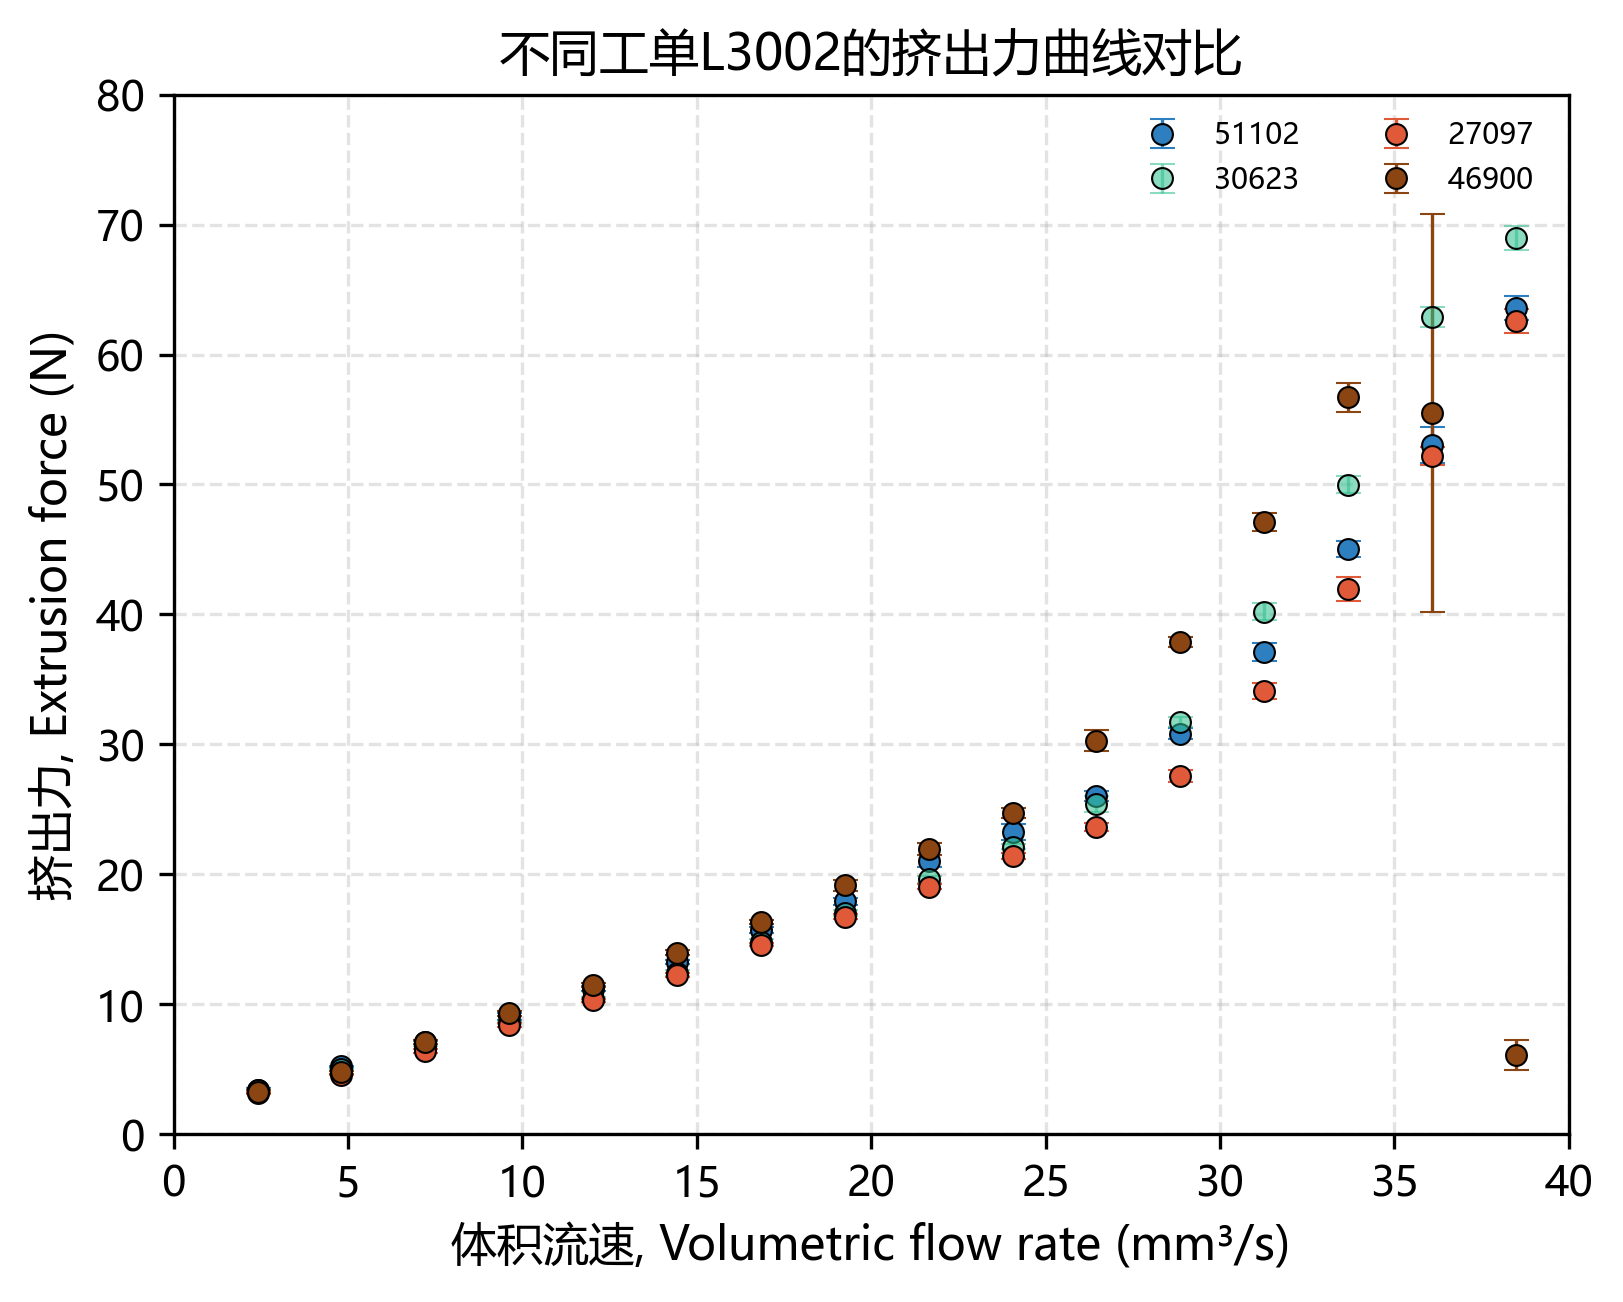

In [7]:
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
# =========================
# 2. 数据整理函数
# =========================
def prepare_data(df):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip()

    # 转换为数值
    df["feedrate_mms"] = pd.to_numeric(df["feedrate_mms"], errors="coerce")
    df["extrusion_force_N_mean"] = pd.to_numeric(df["extrusion_force_N_mean"], errors="coerce")
    df["extrusion_force_N_std"] = pd.to_numeric(df["extrusion_force_N_std"], errors="coerce")

    # 体积流速 = feedrate_mms × π × 0.875²
    df["volume_flow_mm3_s"] = df["feedrate_mms"] * np.pi * 0.875**2

    # 去除无效数据
    df = df.dropna(subset=[
        "volume_flow_mm3_s",
        "extrusion_force_N_mean",
        "extrusion_force_N_std"
    ]).copy()

    # 按体积流速排序
    df = df.sort_values("volume_flow_mm3_s").reset_index(drop=True)

    return df


# =========================
# 4. 设置两个样品名称
# =========================
datasets = [
    {
        "df": data1,
        "label": "51102",
        "color": "#2E7FBF",
        "marker": "o"
    },
    {
        "df": data2,
        "label": "30623",
        "color": "#2EBF8F8F",
        "marker": "o"
    },
    {
        "df": data3,
        "label": "27097",
        "color": "#E05A3A",
        "marker": "o"
    },
    {
       "df": data4,
        "label": "46900",
        "color": "#8B4513",
        "marker": "o"
    }
  #  {
  #      "df": data5,
  #      "label": "36052",
  #      "color": "#FFD700",
  #      "marker": "o"
  #  }
]


# =========================
# 5. 作图
# =========================
fig, ax = plt.subplots(figsize=(6, 4.5), dpi=300)

results = []

for item in datasets:
    df = prepare_data(item["df"])

    label = item["label"]
    color = item["color"]
    marker = item["marker"]

    x = df["volume_flow_mm3_s"].values
    y = df["extrusion_force_N_mean"].values
    yerr = df["extrusion_force_N_std"].values

    # 散点 + 标准差误差棒
    ax.errorbar(
        x,
        y,
        yerr=yerr,
        fmt=marker,
        color=color,
        markersize=5,
        capsize=3,
        linewidth=0,
        elinewidth=0.8,
        markeredgecolor="black",
        markeredgewidth=0.5,
        label=f"{label} "
    )

   


# =========================
# 6. 图形格式
# =========================
ax.set_xlabel("体积流速, Volumetric flow rate (mm³/s)", fontsize=11)
ax.set_ylabel("挤出力, Extrusion force (N)", fontsize=11)
ax.set_title("不同工单L3002的挤出力曲线对比", fontsize=12)

ax.grid(True, linestyle="--", alpha=0.35)
ax.set_xlim(0, 40)
ax.set_ylim(0, 80)
ax.xaxis.set_major_locator(mticker.MaxNLocator(9))
ax.yaxis.set_major_locator(mticker.MaxNLocator(8))

ax.legend(fontsize=7, frameon=False, ncol=2)


# =========================
# 7. 输出拐点结果
# =========================
result_df = pd.DataFrame(results)
print(result_df)

In [20]:
file_path1 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\U0395AU\26.9.1 新质检标准测试\挤出力测试\20260904_140807_U0395AU-2 230℃_stats_clip19.9s.csv"
file_path2 = r"C:\Users\Administrator\Desktop\TPU不同挤出机上测试结果\20260910_102318_U0395AU-2 1号机 BOND TECH_stats_clip20.0s.csv"
file_path3 = r"C:\Users\Administrator\Desktop\TPU不同挤出机上测试结果\20260911_135032_U0395AU-2复测1号机 BOND TECH_stats_clip20.0s.csv"
file_path4 = r"C:\Users\Administrator\Desktop\TPU不同挤出机上测试结果\20260911_125653_U0395AU-2 230℃ 4号机 ORBITER_stats_clip20.0s.csv"
data1 = pd.read_csv(file_path1)
data2 = pd.read_csv(file_path2)
data3 = pd.read_csv(file_path3)
data4 = pd.read_csv(file_path4)

Empty DataFrame
Columns: []
Index: []


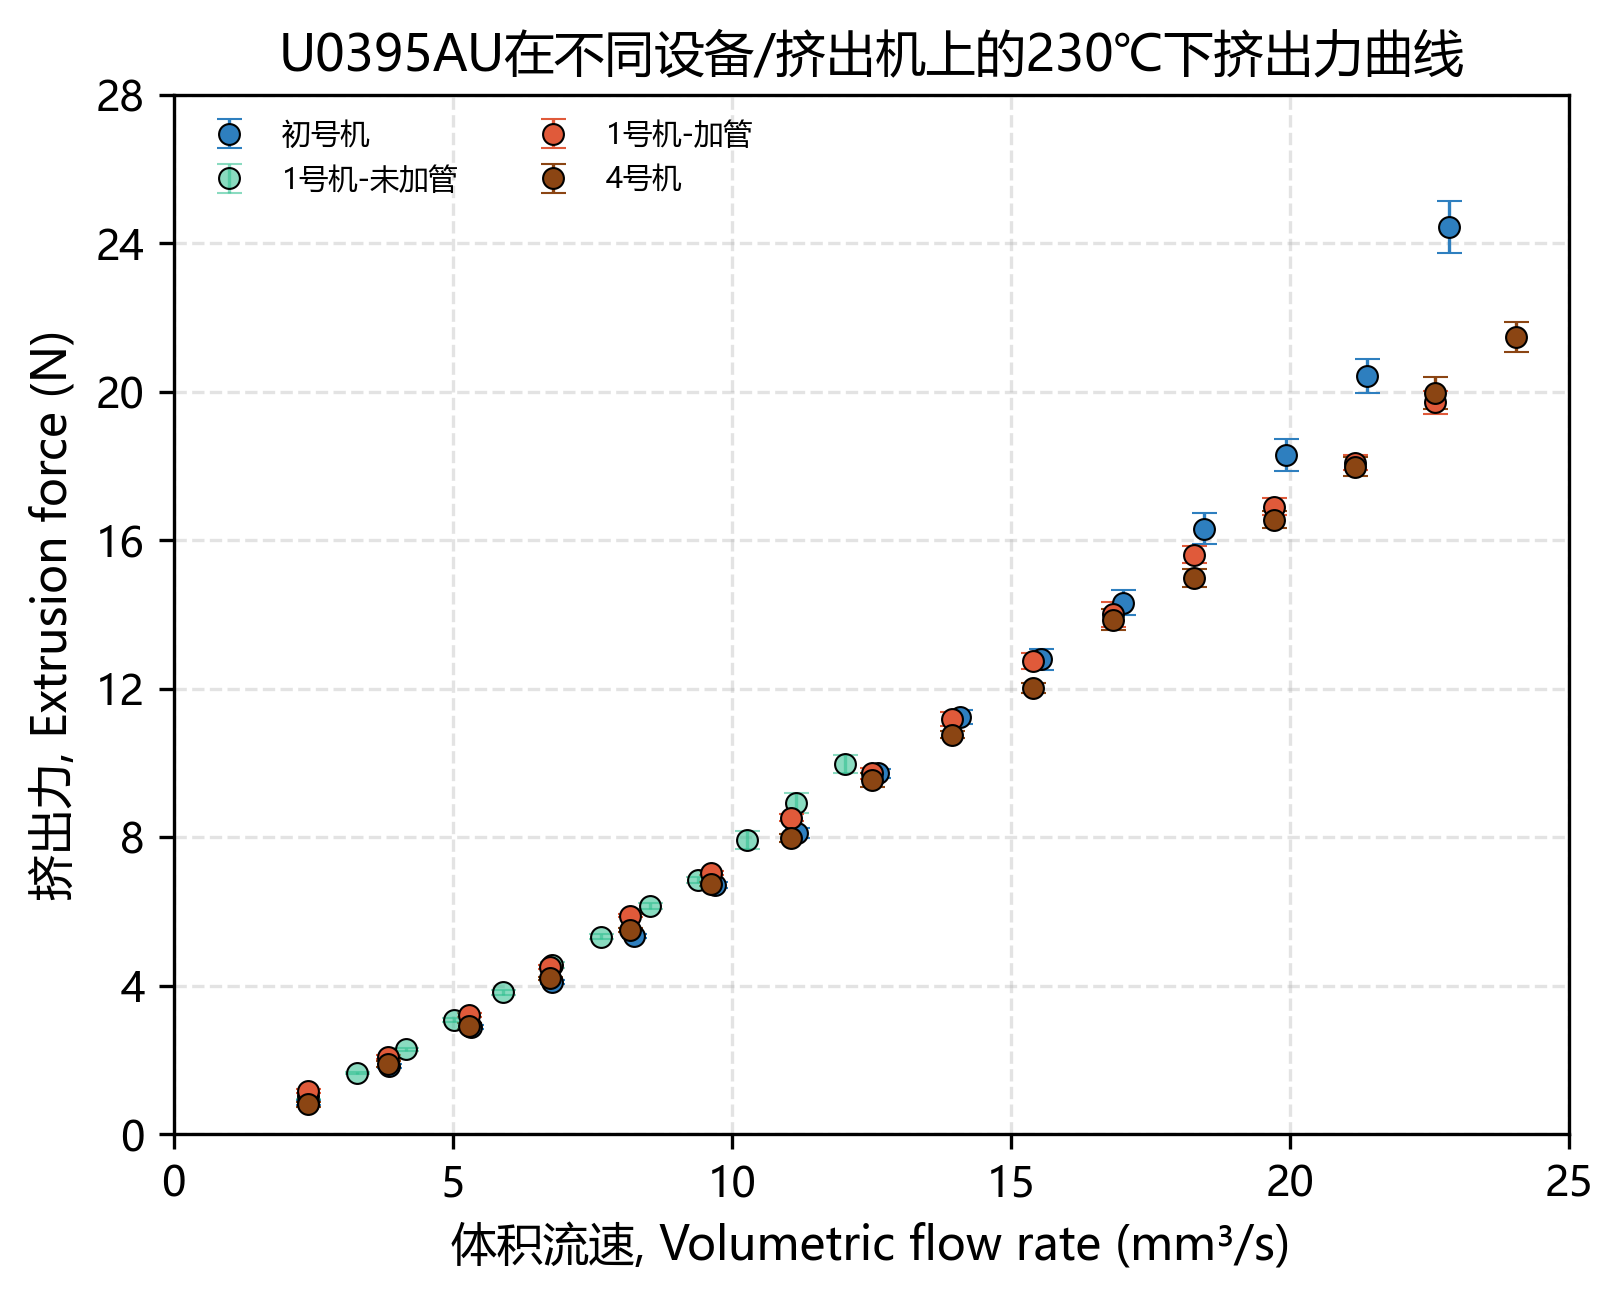

In [21]:
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
# =========================
# 2. 数据整理函数
# =========================
def prepare_data(df):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip()

    # 转换为数值
    df["feedrate_mms"] = pd.to_numeric(df["feedrate_mms"], errors="coerce")
    df["extrusion_force_N_mean"] = pd.to_numeric(df["extrusion_force_N_mean"], errors="coerce")
    df["extrusion_force_N_std"] = pd.to_numeric(df["extrusion_force_N_std"], errors="coerce")

    # 体积流速 = feedrate_mms × π × 0.875²
    df["volume_flow_mm3_s"] = df["feedrate_mms"] * np.pi * 0.875**2

    # 去除无效数据
    df = df.dropna(subset=[
        "volume_flow_mm3_s",
        "extrusion_force_N_mean",
        "extrusion_force_N_std"
    ]).copy()

    # 按体积流速排序
    df = df.sort_values("volume_flow_mm3_s").reset_index(drop=True)

    return df


# =========================
# 4. 设置两个样品名称
# =========================
datasets = [
    {
        "df": data1,
        "label": "初号机",
        "color": "#2E7FBF",
        "marker": "o"
    },
    {
        "df": data2,
        "label": "1号机-未加管",
        "color": "#2EBF8F8F",
        "marker": "o"
    },
    {
        "df": data3,
        "label": "1号机-加管",
        "color": "#E05A3A",
        "marker": "o"
    },
    {
        "df": data4,
        "label": "4号机",
        "color": "#8B4513",
        "marker": "o"
    }
]


# =========================
# 5. 作图
# =========================
fig, ax = plt.subplots(figsize=(6, 4.5), dpi=300)

results = []

for item in datasets:
    df = prepare_data(item["df"])

    label = item["label"]
    color = item["color"]
    marker = item["marker"]

    x = df["volume_flow_mm3_s"].values
    y = df["extrusion_force_N_mean"].values
    yerr = df["extrusion_force_N_std"].values

    # 散点 + 标准差误差棒
    ax.errorbar(
        x,
        y,
        yerr=yerr,
        fmt=marker,
        color=color,
        markersize=5,
        capsize=3,
        linewidth=0,
        elinewidth=0.8,
        markeredgecolor="black",
        markeredgewidth=0.5,
        label=f"{label} "
    )

   


# =========================
# 6. 图形格式
# =========================
ax.set_xlabel("体积流速, Volumetric flow rate (mm³/s)", fontsize=11)
ax.set_ylabel("挤出力, Extrusion force (N)", fontsize=11)
ax.set_title("U0395AU在不同设备/挤出机上的230℃下挤出力曲线", fontsize=12)

ax.grid(True, linestyle="--", alpha=0.35)
ax.set_xlim(0, 25)
ax.set_ylim(0, 28)
ax.xaxis.set_major_locator(mticker.MaxNLocator(6))
ax.yaxis.set_major_locator(mticker.MaxNLocator(8))

ax.legend(fontsize=7, frameon=False, ncol=2)

# =========================
# 7. 输出拐点结果
# =========================
result_df = pd.DataFrame(results)
print(result_df)

In [18]:
file_path1 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\SU311\2026.9.10挤出力曲线测试\20260910_095346_SU311-2 220℃_stats_clip3.0s.csv"
file_path2 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\SU311\2026.9.10挤出力曲线测试\20260910_102025_SU311-2 230℃_stats_clip3.0s.csv"
#file_path3 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\N600CF20\N600CF10 8.12复测\20260812_141341_N600CF20-2 305℃_stats_clip3.0s.csv"
data1 = pd.read_csv(file_path1)
data2 = pd.read_csv(file_path2)
#data3 = pd.read_csv(file_path3)

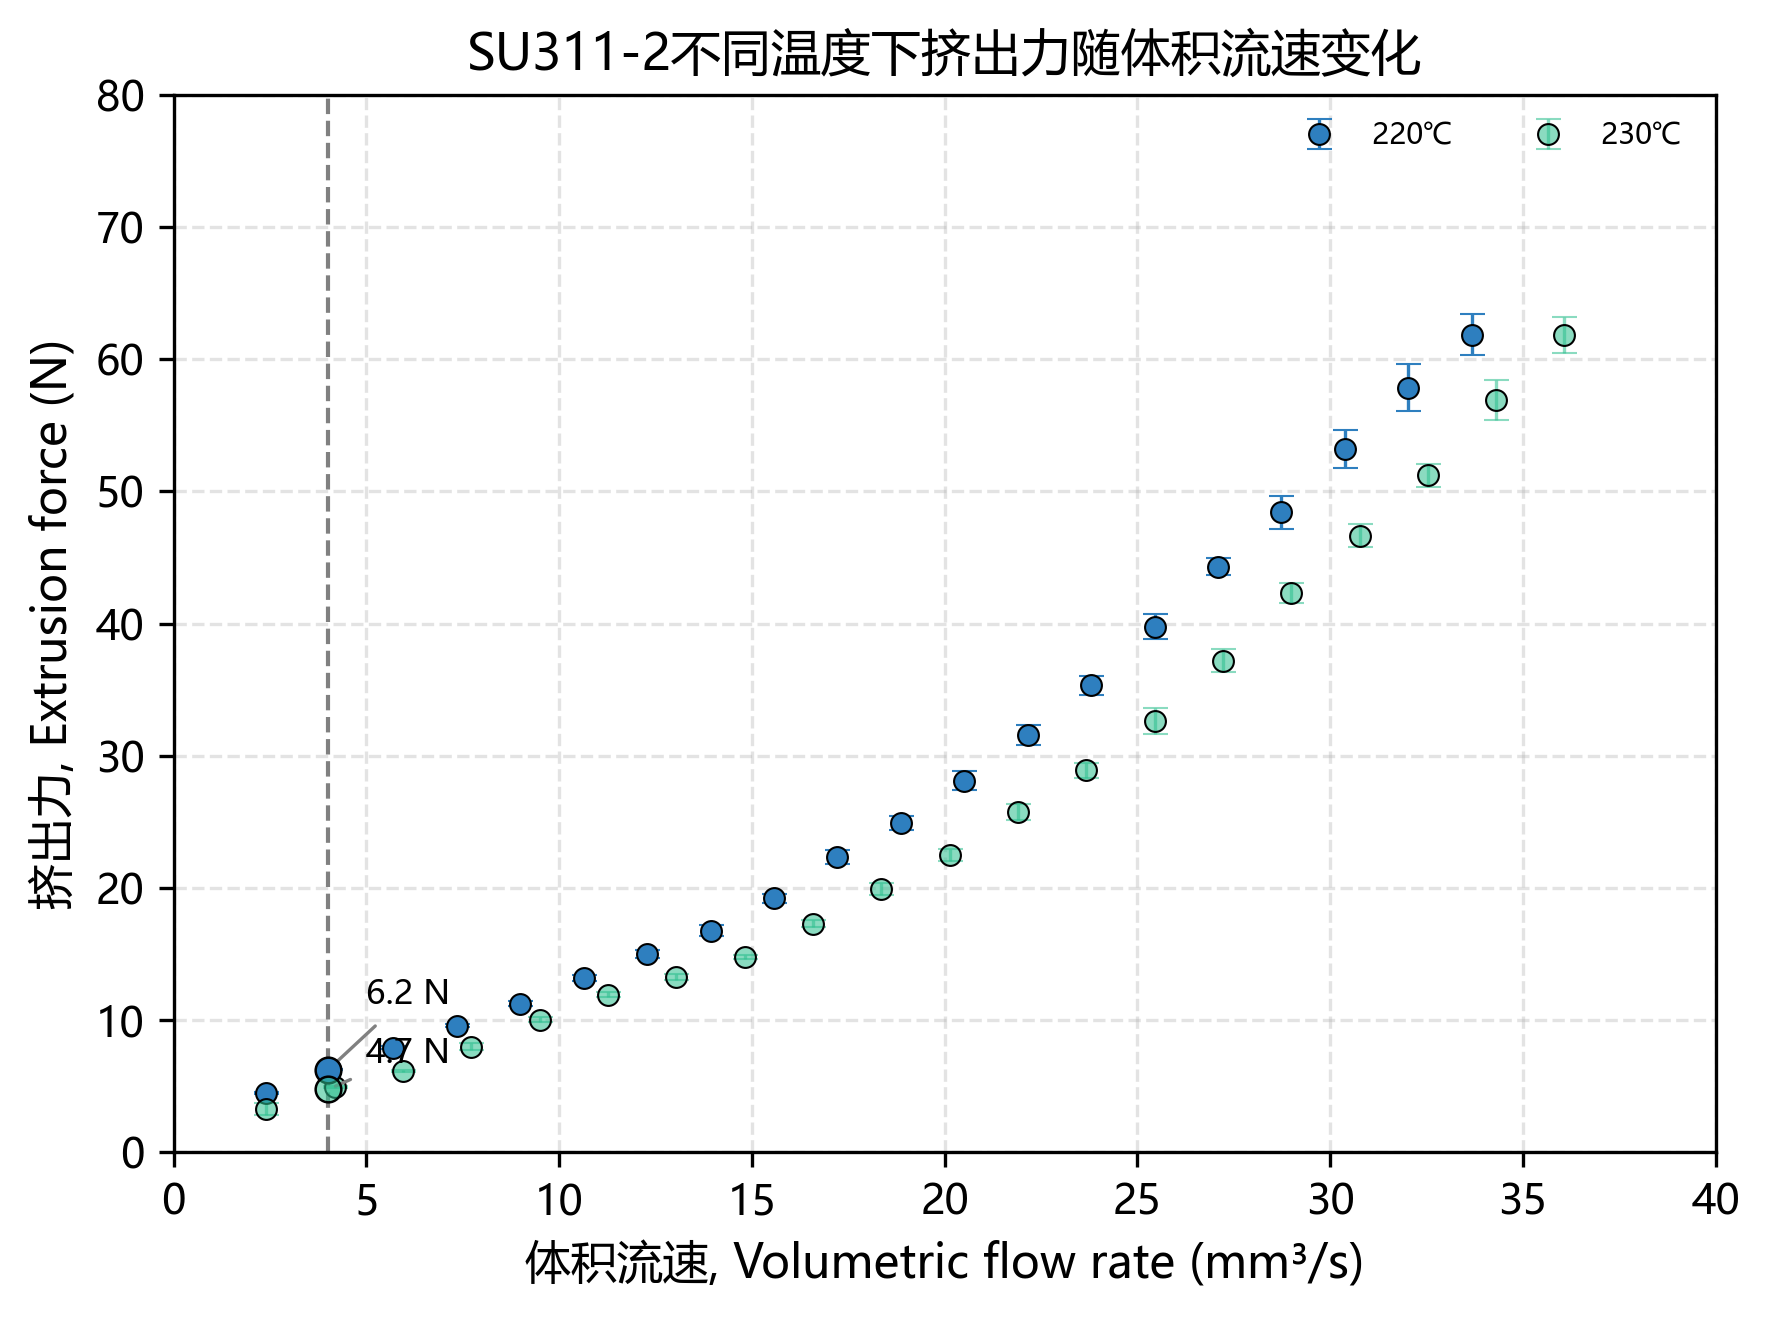

In [19]:
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
# =========================
# 2. 数据整理函数
# =========================
def prepare_data(df):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip()
    # 转换为数值
    df["feedrate_mms"] = pd.to_numeric(df["feedrate_mms"], errors="coerce")
    df["extrusion_force_N_mean"] = pd.to_numeric(df["extrusion_force_N_mean"], errors="coerce")
    df["extrusion_force_N_std"] = pd.to_numeric(df["extrusion_force_N_std"], errors="coerce")
    # 体积流速 = feedrate_mms × π × 0.875²
    df["volume_flow_mm3_s"] = df["feedrate_mms"] * np.pi * 0.875**2
    df = df.dropna(subset=[
        "volume_flow_mm3_s",
        "extrusion_force_N_mean",
        "extrusion_force_N_std"
    ]).copy()

    # 按体积流速排序
    df = df.sort_values("volume_flow_mm3_s").reset_index(drop=True)

    return df
# =========================
# 4. 设置两个样品名称
# =========================
datasets = [
    {
        "df": data1,
        "label": "220℃",
        "color": "#2E7FBF",
        "marker": "o"
    },
    {
        "df": data2,
        "label": "230℃",
        "color": "#2EBF8F8F",
        "marker": "o"
    }
#    {
#        "df": data3,
#        "label": "305℃",
#        "color": "#E05A3A",
#        "marker": "o"
#    }
]

# =========================
# 5. 作图
# =========================
fig, ax = plt.subplots(figsize=(6, 4.5), dpi=300)
VF_target = 4
results = []
for item in datasets:
    df = prepare_data(item["df"])
    label = item["label"]
    color = item["color"]
    marker = item["marker"]
    x = df["volume_flow_mm3_s"].values
    y = df["extrusion_force_N_mean"].values
    yerr = df["extrusion_force_N_std"].values
    # 散点 + 标准差误差棒
    ax.errorbar(
        x,
        y,
        yerr=yerr,
        fmt=marker,
        color=color,
        markersize=5,
        capsize=3,
        linewidth=0,
        elinewidth=0.8,
        markeredgecolor="black",
        markeredgewidth=0.5,
        label=f"{label} "
    )
    # =========================
    # 插值计算 VF=16 时的挤出力
    # =========================
    if x.min() <= VF_target <= x.max():
        #线性插值
        F16 = np.interp(VF_target, x, y)
        #保存结果
        results.append({
            "Temperature": label,
            "VF": VF_target,
            "ExtrusionForce": F16
        })
        # 在曲线上画出插值点
        ax.scatter(
            VF_target,
            F16,
            s=38,
            color=color,
            edgecolors="black",
            linewidth=0.6,
            zorder=5
        )
# =========================
# =========================
# VF=16竖线
# =========================
ax.axvline(
    VF_target,
    color="gray",
    linestyle="--",
    linewidth=1
)

# 为了防止文字重叠，给三个标注不同偏移
offsets = [5, 2, -3]
#offsets = [10, 5]

for i, r in enumerate(results):

    ax.annotate(
        f'{r["ExtrusionForce"]:.1f} N',
        xy=(VF_target, r["ExtrusionForce"]),
        xytext=(VF_target + 1,
                r["ExtrusionForce"] + offsets[i]),
        fontsize=8,
        color="black",
        arrowprops=dict(
            arrowstyle="-",
            lw=0.8,
            color="gray"
        )
    )
# 6. 图形格式
# =========================
ax.set_xlabel("体积流速, Volumetric flow rate (mm³/s)", fontsize=11)
ax.set_ylabel("挤出力, Extrusion force (N)", fontsize=11)
ax.set_title("SU311-2不同温度下挤出力随体积流速变化", fontsize=12)

ax.grid(True, linestyle="--", alpha=0.35)
ax.set_xlim(0, 40)
ax.set_ylim(0, 80)
ax.xaxis.set_major_locator(mticker.MaxNLocator(9))
ax.yaxis.set_major_locator(mticker.MaxNLocator(9))

ax.legend(fontsize=7, frameon=False, ncol=2)

plt.tight_layout()
plt.show()

In [66]:
file_path1 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\U0390A\U0390AU挤出力测试\20260904_150121_U0390AU-2 205℃_stats_clip19.9s.csv"
file_path2 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\U0390A\U0390AU挤出力测试\20260904_152101_U0390AU-2 225℃_stats_clip19.9s.csv"
file_path3 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\U0390A\U0390AU挤出力测试\20260904_154340_U0390AU-2 240℃_stats_clip19.9s.csv"
data1 = pd.read_csv(file_path1)
data2 = pd.read_csv(file_path2)
data3 = pd.read_csv(file_path3)

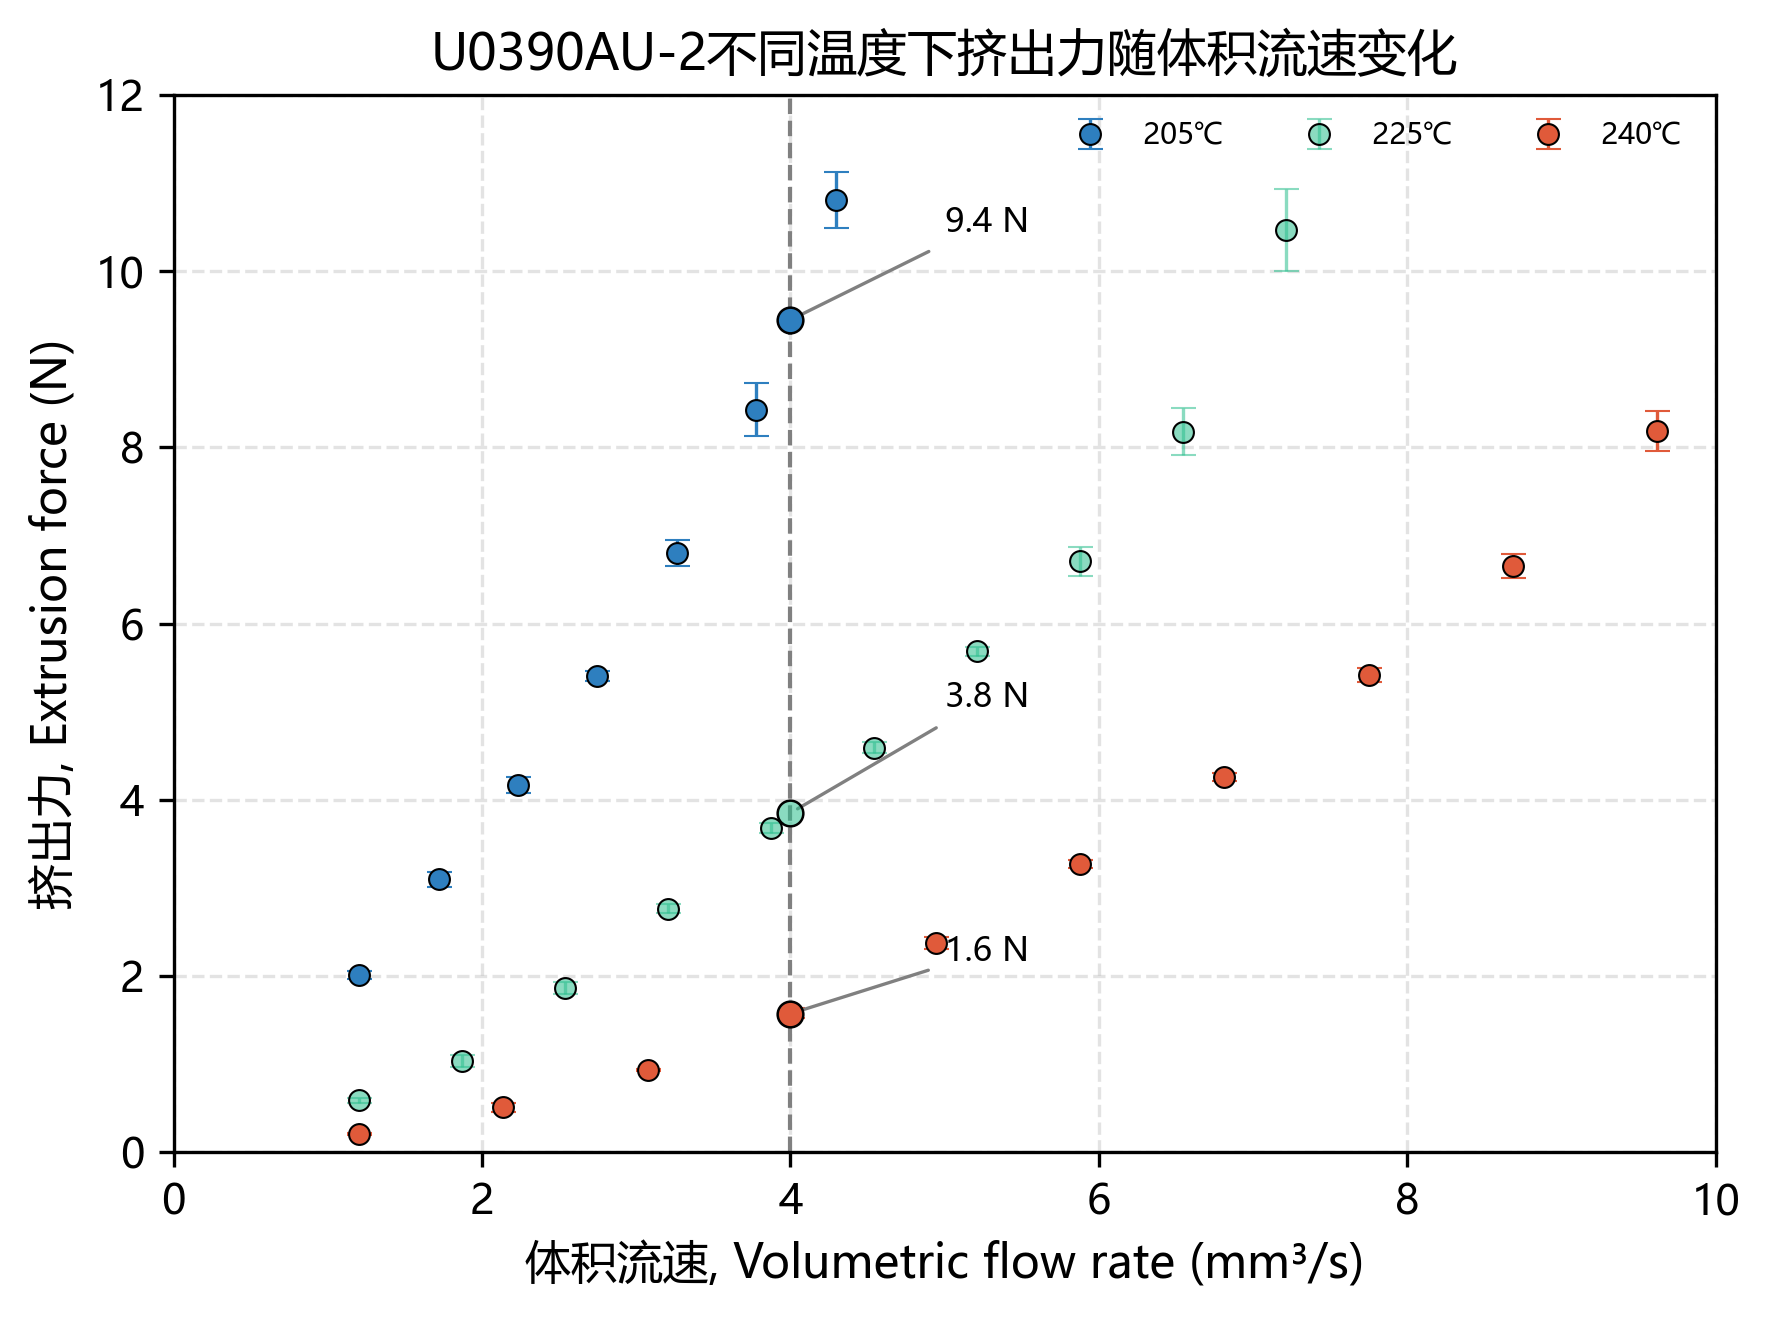

In [76]:
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
# =========================
# 2. 数据整理函数
# =========================
def prepare_data(df):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip()
    # 转换为数值
    df["feedrate_mms"] = pd.to_numeric(df["feedrate_mms"], errors="coerce")
    df["extrusion_force_N_mean"] = pd.to_numeric(df["extrusion_force_N_mean"], errors="coerce")
    df["extrusion_force_N_std"] = pd.to_numeric(df["extrusion_force_N_std"], errors="coerce")
    # 体积流速 = feedrate_mms × π × 0.875²
    df["volume_flow_mm3_s"] = df["feedrate_mms"] * np.pi * 0.875**2
    df = df.dropna(subset=[
        "volume_flow_mm3_s",
        "extrusion_force_N_mean",
        "extrusion_force_N_std"
    ]).copy()

    # 按体积流速排序
    df = df.sort_values("volume_flow_mm3_s").reset_index(drop=True)

    return df
# =========================
# 4. 设置两个样品名称
# =========================
datasets = [
    {
        "df": data1,
        "label": "205℃",
        "color": "#2E7FBF",
        "marker": "o"
    },
    {
        "df": data2,
        "label": "225℃",
        "color": "#2EBF8F8F",
        "marker": "o"
    },
    {
        "df": data3,
        "label": "240℃",
        "color": "#E05A3A",
        "marker": "o"
    }
]

# =========================
# 5. 作图
# =========================
fig, ax = plt.subplots(figsize=(6, 4.5), dpi=300)
VF_target = 4
results = []
for item in datasets:
    df = prepare_data(item["df"])
    label = item["label"]
    color = item["color"]
    marker = item["marker"]
    x = df["volume_flow_mm3_s"].values
    y = df["extrusion_force_N_mean"].values
    yerr = df["extrusion_force_N_std"].values
    # 散点 + 标准差误差棒
    ax.errorbar(
        x,
        y,
        yerr=yerr,
        fmt=marker,
        color=color,
        markersize=5,
        capsize=3,
        linewidth=0,
        elinewidth=0.8,
        markeredgecolor="black",
        markeredgewidth=0.5,
        label=f"{label} "
    )
    # =========================
    # 插值计算 VF=16 时的挤出力
    # =========================
    if x.min() <= VF_target <= x.max():
        #线性插值
        F16 = np.interp(VF_target, x, y)
        #保存结果
        results.append({
            "Temperature": label,
            "VF": VF_target,
            "ExtrusionForce": F16
        })
        # 在曲线上画出插值点
        ax.scatter(
            VF_target,
            F16,
            s=38,
            color=color,
            edgecolors="black",
            linewidth=0.6,
            zorder=5
        )
# =========================
# =========================
# VF=16竖线
# =========================
ax.axvline(
    VF_target,
    color="gray",
    linestyle="--",
    linewidth=1
)

# 为了防止文字重叠，给三个标注不同偏移
offsets = [1, 1.2, 0.6]
#offsets = [10, 5]

for i, r in enumerate(results):

    ax.annotate(
        f'{r["ExtrusionForce"]:.1f} N',
        xy=(VF_target, r["ExtrusionForce"]),
        xytext=(VF_target + 1,
                r["ExtrusionForce"] + offsets[i]),
        fontsize=8,
        color="black",
        arrowprops=dict(
            arrowstyle="-",
            lw=0.8,
            color="gray"
        )
    )
# 6. 图形格式
# =========================
ax.set_xlabel("体积流速, Volumetric flow rate (mm³/s)", fontsize=11)
ax.set_ylabel("挤出力, Extrusion force (N)", fontsize=11)
ax.set_title("U0390AU-2不同温度下挤出力随体积流速变化", fontsize=12)

ax.grid(True, linestyle="--", alpha=0.35)
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)
ax.xaxis.set_major_locator(mticker.MaxNLocator(6))
ax.yaxis.set_major_locator(mticker.MaxNLocator(7))

ax.legend(fontsize=7, frameon=False, ncol=11)

plt.tight_layout()
plt.show()

# 挤出力质检标准测试数据汇总

In [ ]:
file_path = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\数据汇总\拐点与网格最大体积流速.xlsx"
data = pd.read_excel(file_path)

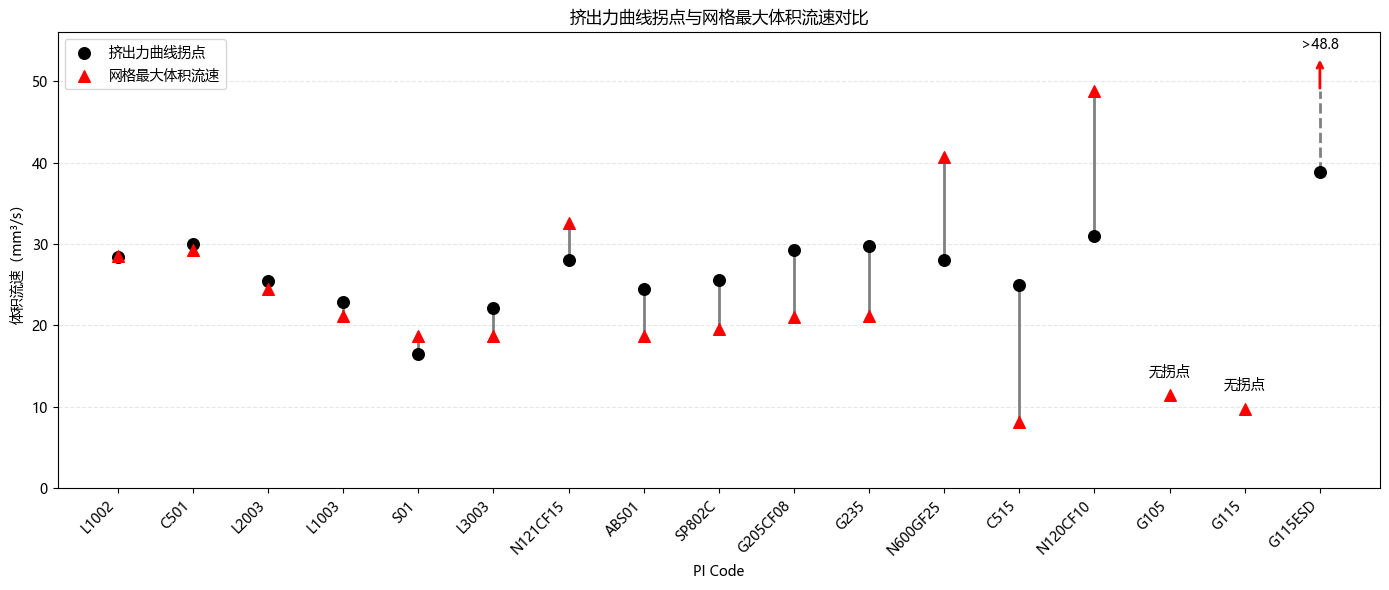

In [7]:
# 设置中文字体
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]  # 微软雅黑
plt.rcParams["axes.unicode_minus"] = False             # 正常显示负号
file = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\数据汇总\拐点与网格最大体积流速.xlsx"
df = pd.read_excel(file)


# 只取需要的三列
df = df.iloc[:, [0, 2, 3]]
df.columns = ["PI Code", "拐点", "网格流速"]


def is_number(x):
    try:
        float(x)
        return True
    except:
        return False


# =========================
# 正常数据
# =========================
normal = df[
    df["拐点"].apply(is_number) &
    df["网格流速"].apply(is_number)
].copy()

normal["拐点"] = normal["拐点"].astype(float)
normal["网格流速"] = normal["网格流速"].astype(float)

normal["差值"] = abs(normal["拐点"] - normal["网格流速"])

# 按绝对差值从小到大排列
normal = normal.sort_values("差值")


# =========================
# 特殊数据放最后
# =========================
special = df.drop(normal.index)

plot_df = pd.concat([normal, special], ignore_index=True)


# =========================
# 绘图
# =========================
plt.figure(figsize=(14, 6))

x = np.arange(len(plot_df))

for i, row in plot_df.iterrows():

    y1 = row["拐点"]
    y2 = row["网格流速"]

    # -------------------------
    # 正常数据
    # -------------------------
    if is_number(y1) and is_number(y2):

        y1 = float(y1)
        y2 = float(y2)

        # 连接线
        plt.plot(
            [i, i],
            [y1, y2],
            color="gray",
            linewidth=2
        )

        # 挤出力曲线拐点
        plt.scatter(
            i, y1,
            color="black",
            marker="o",
            s=70,
            zorder=3
        )

        # 网格最大体积流速
        plt.scatter(
            i, y2,
            color="red",
            marker="^",
            s=70,
            zorder=3
        )


    # -------------------------
    # 无拐点
    # -------------------------
    elif str(y1).strip() == "无拐点":

        if is_number(y2):

            y2 = float(y2)

            # 网格最大体积流速正常画出来
            plt.scatter(
                i, y2,
                color="red",
                marker="^",
                s=70,
                zorder=3
            )

            # 把“无拐点”直接写在该PI Code竖直方向上
            plt.text(
                i,
                y2 + 2,
                "无拐点",
                ha="center",
                va="bottom",
                fontsize=10
            )


    # -------------------------
    # >48.8 或 ＞48.8
    # -------------------------
    elif (">" in str(y2)) or ("＞" in str(y2)):

        if is_number(y1):

            y1 = float(y1)

            # 同时兼容中文 ＞ 和英文 >
            value = str(y2).replace("＞", ">")
            limit = float(value.replace(">", "").strip())

            # 挤出力曲线拐点
            plt.scatter(
                i, y1,
                color="black",
                marker="o",
                s=70,
                zorder=3
            )

            # 从拐点连接到测试上限
            plt.plot(
                [i, i],
                [y1, limit],
                color="gray",
                linestyle="--",
                linewidth=2
            )

            # 从48.8继续向上画箭头
            plt.annotate(
                "",
                xy=(i, 53),
                xytext=(i, limit),
                arrowprops=dict(
                    arrowstyle="->",
                    color="red",
                    linewidth=2
                )
            )

            # 标出 >48.8
            plt.text(
                i,
                53.5,
                f">{limit}",
                ha="center",
                va="bottom",
                fontsize=10
            )


# =========================
# 图例
# =========================
plt.scatter(
    [], [],
    color="black",
    marker="o",
    s=70,
    label="挤出力曲线拐点"
)

plt.scatter(
    [], [],
    color="red",
    marker="^",
    s=70,
    label="网格最大体积流速"
)

plt.legend()


# =========================
# 坐标轴
# =========================
plt.xticks(
    x,
    plot_df["PI Code"],
    rotation=45,
    ha="right"
)

plt.xlabel("PI Code")
plt.ylabel("体积流速（mm³/s）")

plt.title("挤出力曲线拐点与网格最大体积流速对比")

# 因为 G115ESD >48.8，
# 手动把纵坐标上限提高，给箭头和文字留空间
plt.ylim(0, 56)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [8]:
## PLA不同PI Code的挤出力曲线对比（220℃）

In [32]:
file_path1 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\L1002白色\26.6.15 L1002最新版本—设计自动开始或结束记录自动清零后\20260615_133726_L1002-2 220℃_stats_clip30.csv"
file_path2 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\L2002 大理石白\20260717最新\20260717_151340_L2002黑220℃_stats_clip3.0s.csv"
file_path3 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260720-L1013\20260720_155416_L1013-1-220℃_stats_clip3.0s.csv"
file_path4 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260817\20260817_163813_L3003-1-220℃_stats_clip3.0s.csv"
file_path5 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\L1003\L1003\20260729_164451_L1003-2 220℃_stats_clip3.0s.csv"
file_path6 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260814\20260814_125502_L1005-2-220℃_stats_clip3.0s.csv"
file_path7 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260722\20260722_105002_L4004-2-220℃_stats_clip3.0s.csv"
file_path8 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260723\L4004GF12\20260723_164808_L4004GF12-2-220℃_stats_clip3.0s.csv"
file_path9 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\L1009\20260810_145857_L1009-1 220℃_stats_clip3.0s.csv"
file_path10 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\L3001\L3001 26.7.24\处理后\20260724_094254_L3001-2 220℃_stats_clip3.0s.csv"
file_path11 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260811\20260811_150626_L2002CF-2-220℃_stats_clip3.0s.csv"
file_path12 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260811\20260811_124808_L2003-1-220℃_stats_clip3.0s.csv"
file_path13 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\L3002\20260324_L3002-1 220℃_stats_clip3.0s.csv"
data1 = pd.read_csv(file_path1)
data2 = pd.read_csv(file_path2)
data3 = pd.read_csv(file_path3)
data4 = pd.read_csv(file_path4)
data5 = pd.read_csv(file_path5)
data6 = pd.read_csv(file_path6)
data7 = pd.read_csv(file_path7)
data8 = pd.read_csv(file_path8)
data9 = pd.read_csv(file_path9)
data10 = pd.read_csv(file_path10)
data11 = pd.read_csv(file_path11)
data12 = pd.read_csv(file_path12)
data13 = pd.read_csv(file_path13)

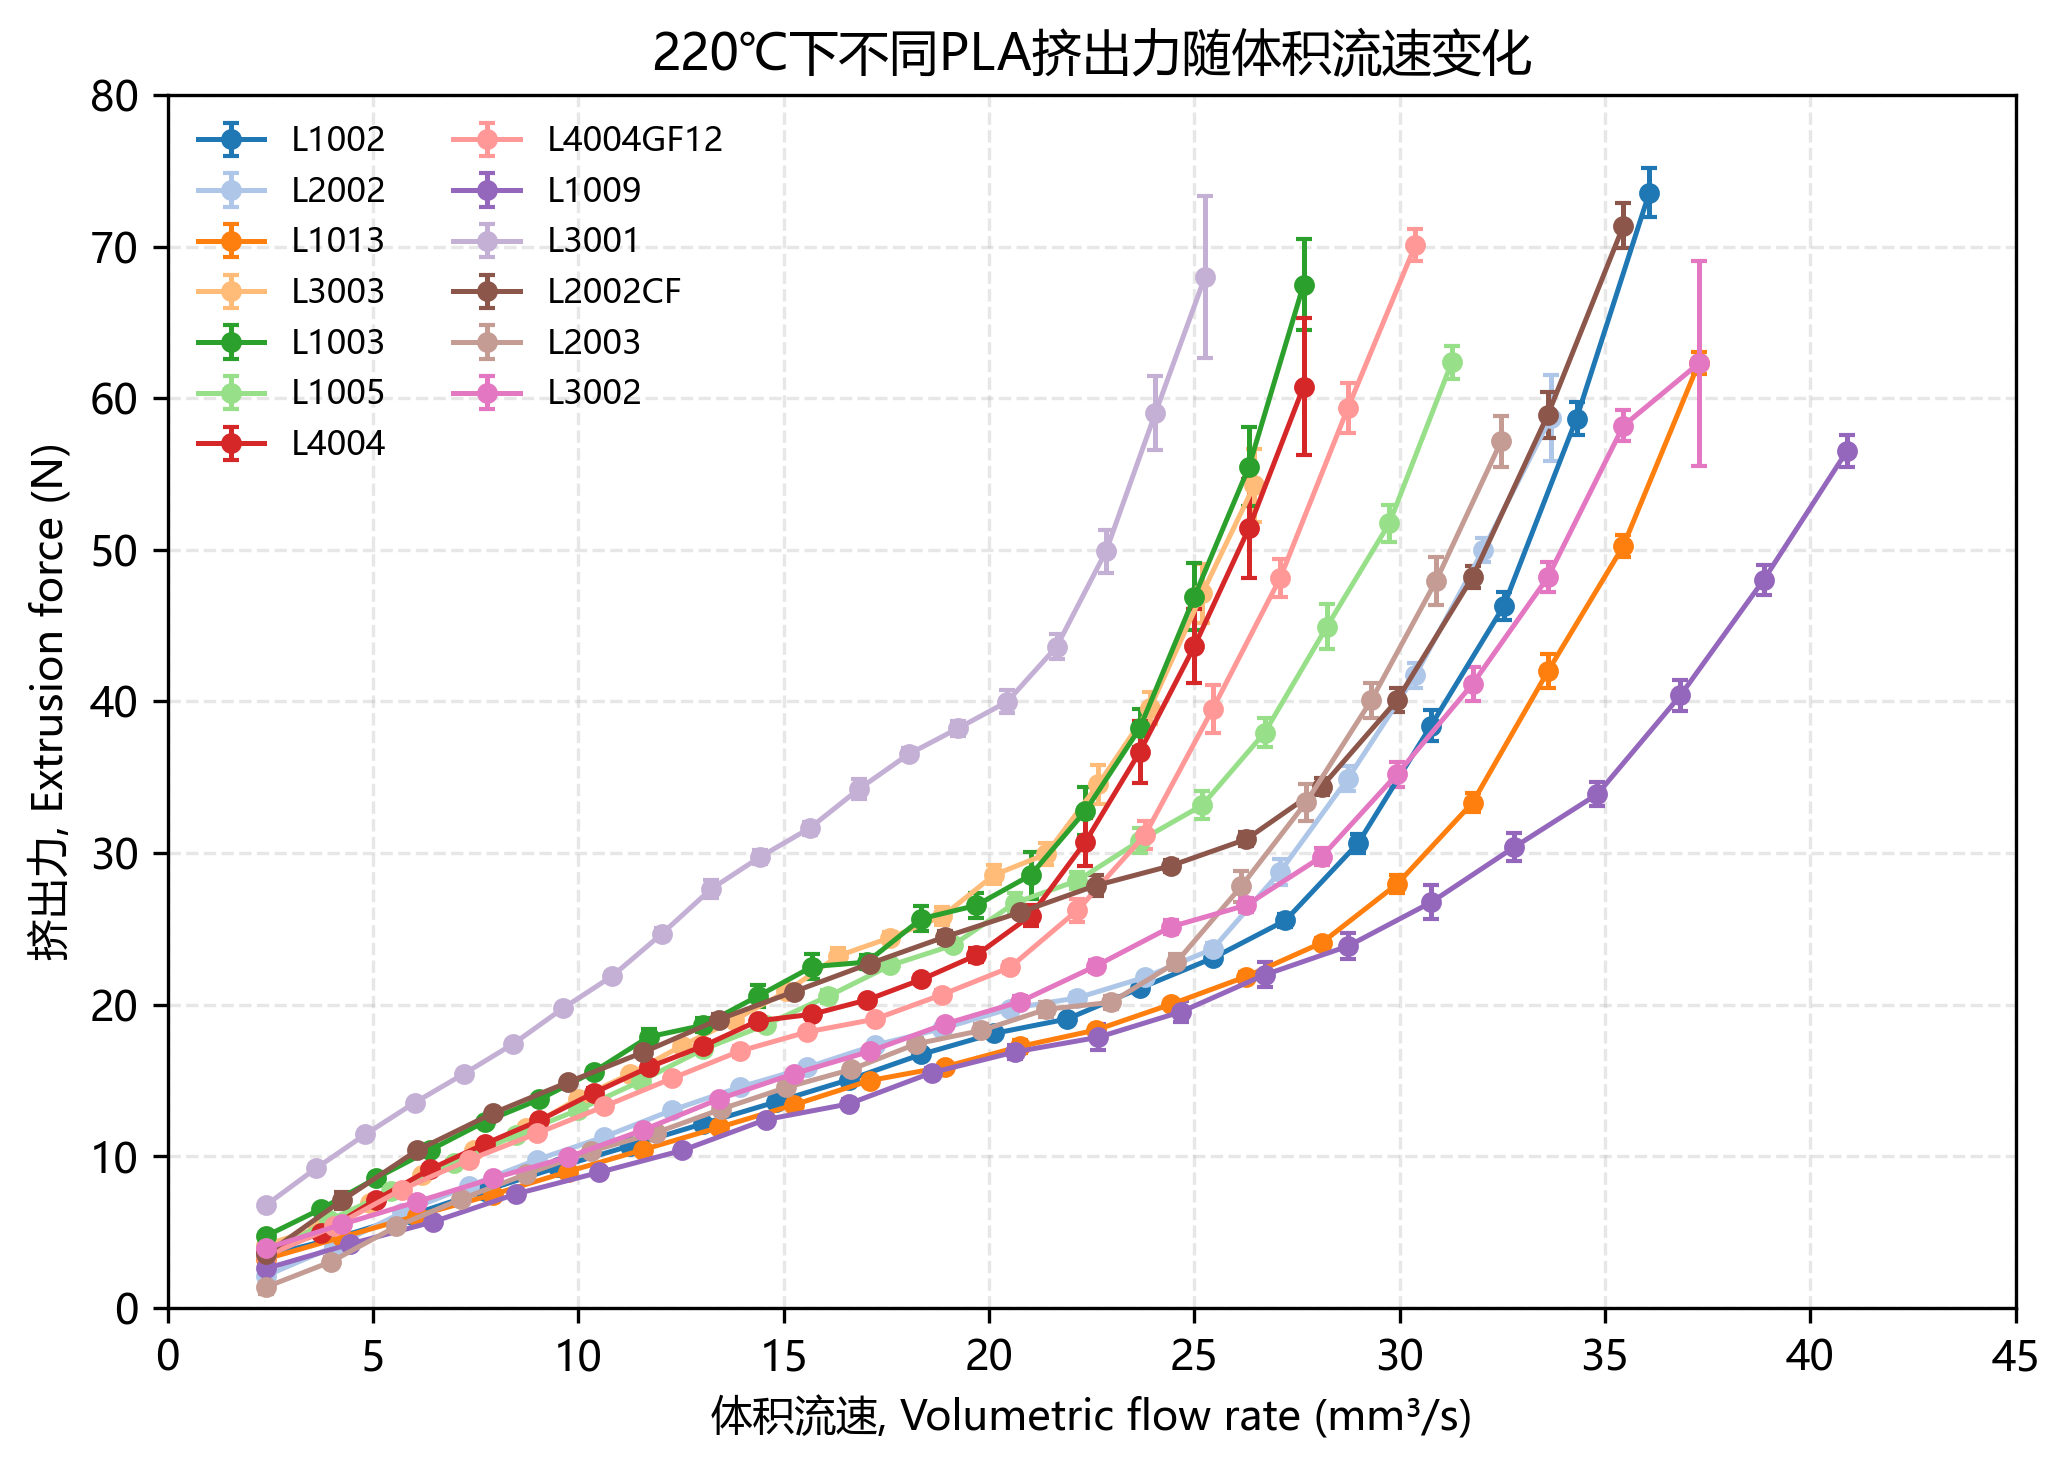

In [33]:
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
# =========================
# 数据
# =========================
datasets = {
    "L1002": data1,
    "L2002": data2,
    "L1013": data3,
    "L3003": data4,
    "L1003": data5,
    "L1005": data6,
    "L4004": data7,
    "L4004GF12": data8,
    "L1009": data9,
    "L3001": data10,
    "L2002CF": data11,
    "L2003": data12,
    "L3002": data13
}

# =========================
# 作图
# =========================
fig, ax = plt.subplots(figsize=(7, 5), dpi=300)
ax.set_prop_cycle(color=plt.cm.tab20.colors)
for label, df in datasets.items():

    # 转换为数值
    feedrate = pd.to_numeric(df["feedrate_mms"], errors="coerce")
    force = pd.to_numeric(df["extrusion_force_N_mean"], errors="coerce")
    force_std = pd.to_numeric(df["extrusion_force_N_std"], errors="coerce")

    # 体积流速
    flow = feedrate * np.pi * 0.875**2

    # 去掉无效值
    valid = flow.notna() & force.notna() & force_std.notna()

    flow = flow[valid]
    force = force[valid]
    force_std = force_std[valid]

    # 按体积流速排序
    order = np.argsort(flow)
    flow = flow.iloc[order]
    force = force.iloc[order]
    force_std = force_std.iloc[order]

    # 曲线 + 数据点 + 标准差
    ax.errorbar(
        flow,
        force,
        yerr=force_std,
        fmt="o-",
        markersize=4,
        linewidth=1.2,
        capsize=2,
        label=label
    )


# =========================
# 图形设置
# =========================
ax.set_xlabel("体积流速, Volumetric flow rate (mm³/s)")
ax.set_ylabel("挤出力, Extrusion force (N)")
ax.set_title("220℃下不同PLA挤出力随体积流速变化")

ax.set_xlim(0, 45)
ax.set_ylim(0, 80)

ax.grid(linestyle="--", alpha=0.3)
ax.legend(fontsize=8, frameon=False, ncol=2)

plt.tight_layout()
plt.show()

In [26]:
file_path1 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\G105\20260723_151435_G105-1-250℃_stats_clip3.0s.csv"
file_path2 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\G115\G115挤出力测试数据\20260805_111124_G115-1 250℃复测_stats_clip3.0s.csv"
file_path3 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260806\20260806_134003_G205CF08-1-250℃_stats_clip3.0s.csv"
file_path4 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\G115ESD\260729 G115ESD\20260729_132807_G115ESD-1 250℃_stats_clip3.0s.csv"
data1 = pd.read_csv(file_path1)
data2 = pd.read_csv(file_path2)
data3 = pd.read_csv(file_path3)
data4 = pd.read_csv(file_path4)

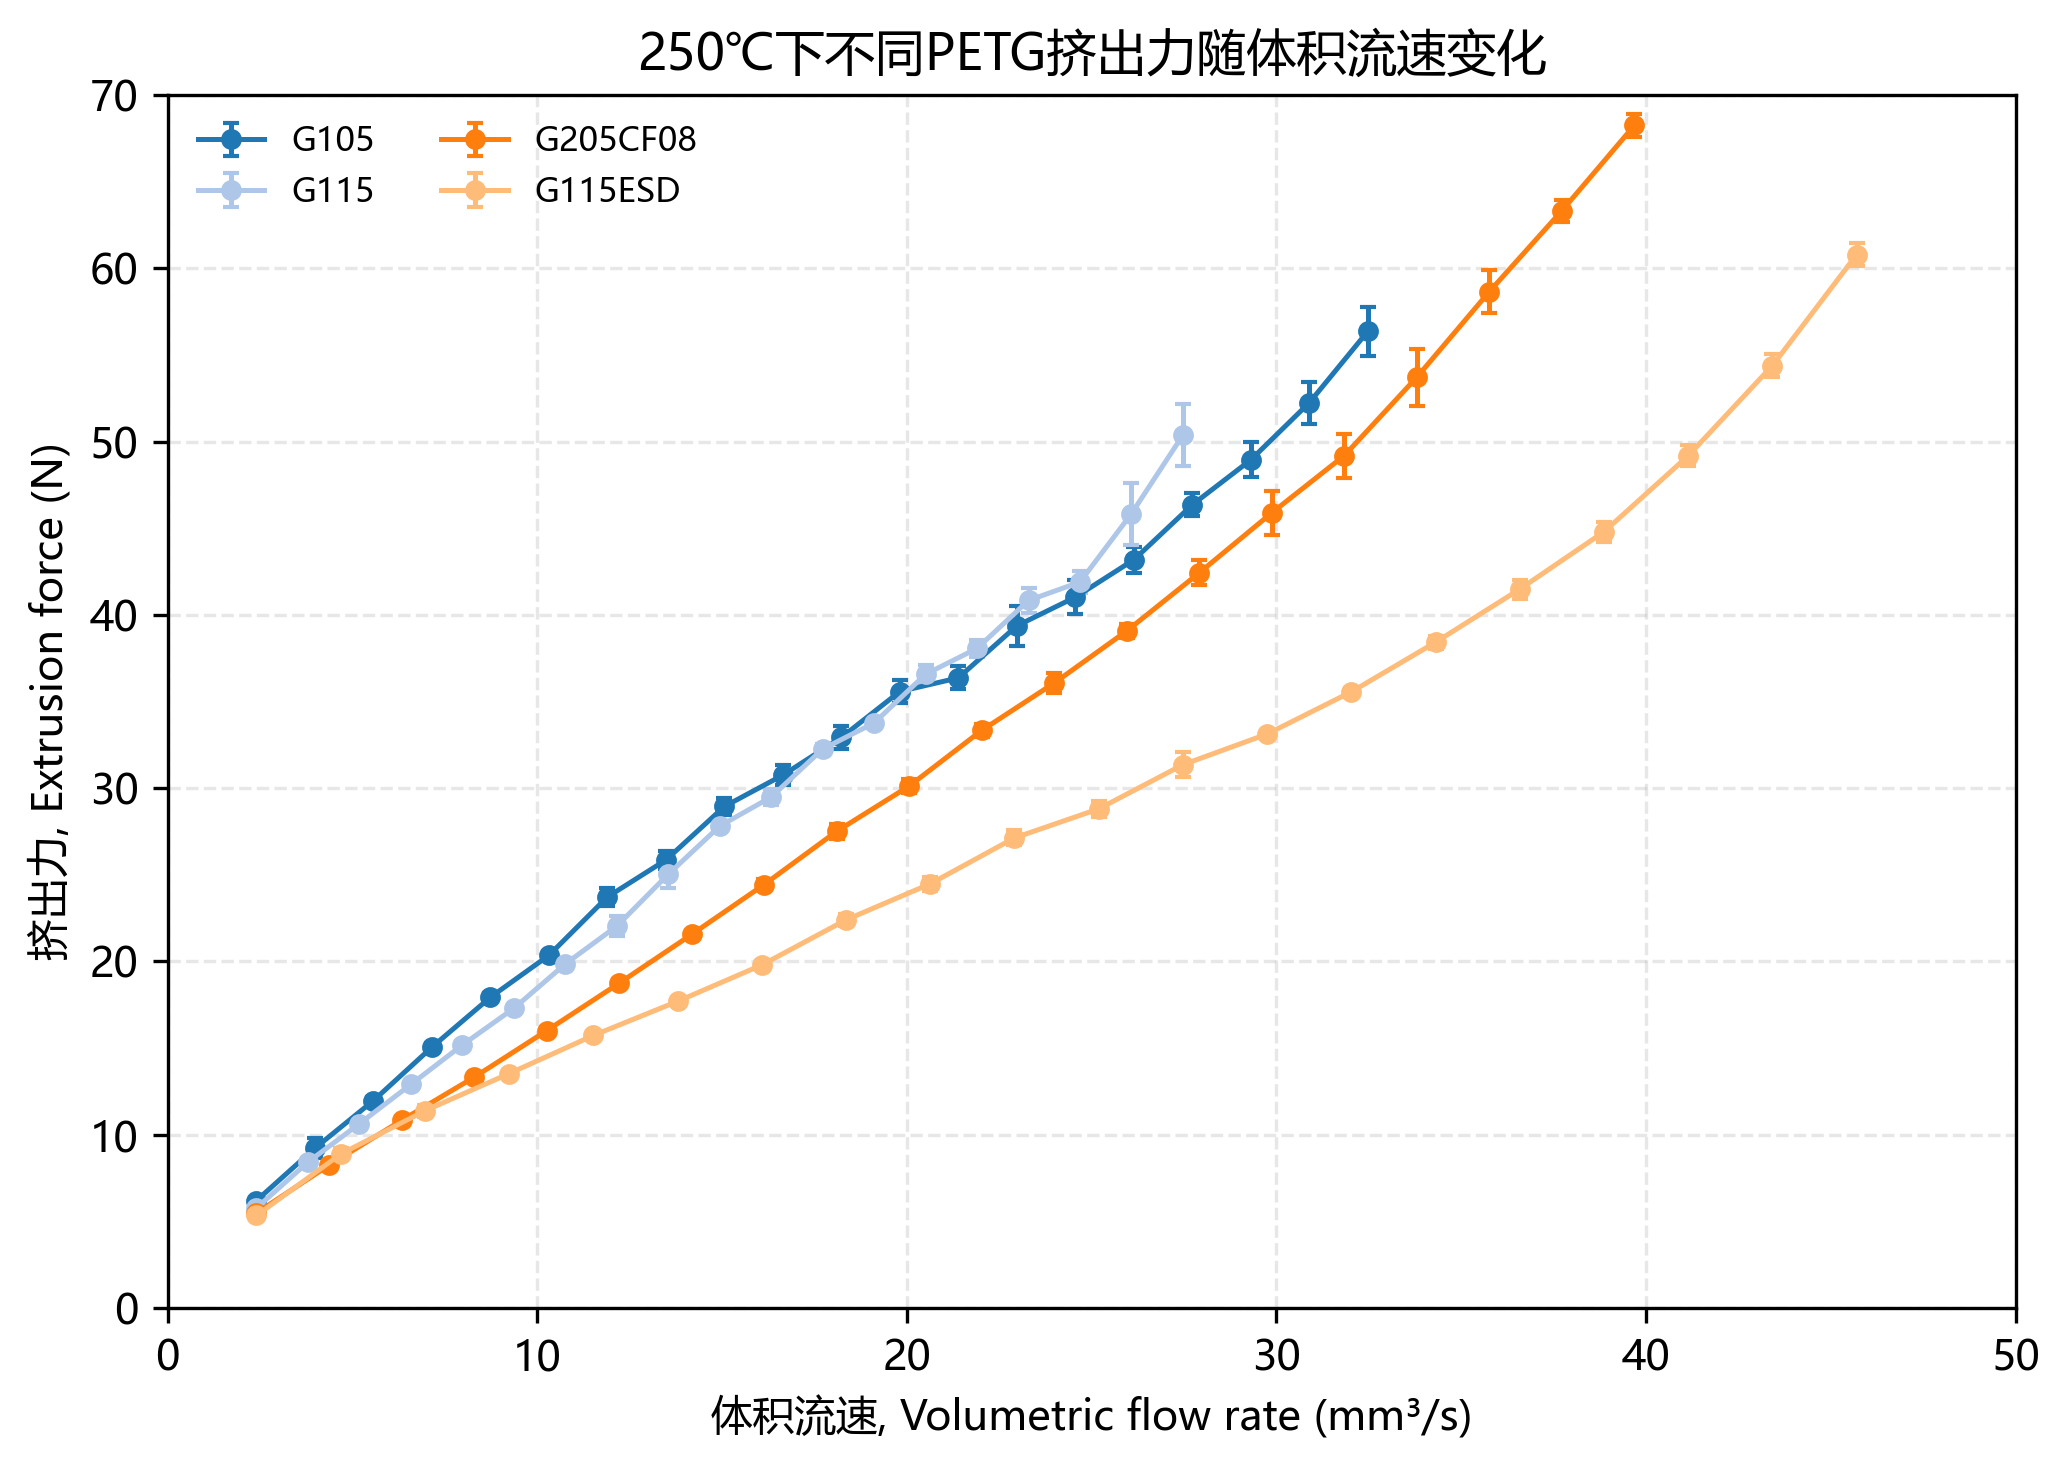

In [27]:
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
# =========================
# 数据
# =========================
datasets = {
    "G105": data1,
    "G115": data2,
    "G205CF08": data3,
    "G115ESD": data4
}
# =========================
# 作图
# =========================
fig, ax = plt.subplots(figsize=(7, 5), dpi=300)
ax.set_prop_cycle(color=plt.cm.tab20.colors)
for label, df in datasets.items():

    # 转换为数值
    feedrate = pd.to_numeric(df["feedrate_mms"], errors="coerce")
    force = pd.to_numeric(df["extrusion_force_N_mean"], errors="coerce")
    force_std = pd.to_numeric(df["extrusion_force_N_std"], errors="coerce")

    # 体积流速
    flow = feedrate * np.pi * 0.875**2

    # 去掉无效值
    valid = flow.notna() & force.notna() & force_std.notna()

    flow = flow[valid]
    force = force[valid]
    force_std = force_std[valid]

    # 按体积流速排序
    order = np.argsort(flow)
    flow = flow.iloc[order]
    force = force.iloc[order]
    force_std = force_std.iloc[order]

    # 曲线 + 数据点 + 标准差
    ax.errorbar(
        flow,
        force,
        yerr=force_std,
        fmt="o-",
        markersize=4,
        linewidth=1.2,
        capsize=2,
        label=label
    )


# =========================
# 图形设置
# =========================
ax.set_xlabel("体积流速, Volumetric flow rate (mm³/s)")
ax.set_ylabel("挤出力, Extrusion force (N)")
ax.set_title("250℃下不同PETG挤出力随体积流速变化")

ax.set_xlim(0, 50)
ax.set_ylim(0, 70)

ax.grid(linestyle="--", alpha=0.3)
ax.legend(fontsize=8, frameon=False, ncol=2)

plt.tight_layout()
plt.show()

In [34]:
file_path1 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260814\20260814_161250_N703CB-2-260℃_stats_clip3.0s.csv"
file_path2 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\N600CF20\N600CF10 8.12复测\20260812_110523_N600CF20-1 260℃_stats_clip3.0s.csv"
file_path3 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\N600GF25\N600GF25挤出力测试结果\20260805_180510_N600GF25-2 260℃_stats_clip3.0s.csv"
file_path4 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\N121CF10ESD\20260810_132817_N121CF10ESD-2 260℃_stats_clip3.0s.csv"
file_path5 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260806\20260806_092308_N121CF15-1-260℃_stats_clip3.0s.csv"
file_path6 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\N120CF10\N120CF10挤出力测试数据\20260805_155027_N120CF10-1 260℃_stats_clip3.0s.csv"
data1 = pd.read_csv(file_path1)
data2 = pd.read_csv(file_path2)
data3 = pd.read_csv(file_path3)
data4 = pd.read_csv(file_path4)
data5 = pd.read_csv(file_path5)
data6 = pd.read_csv(file_path6)

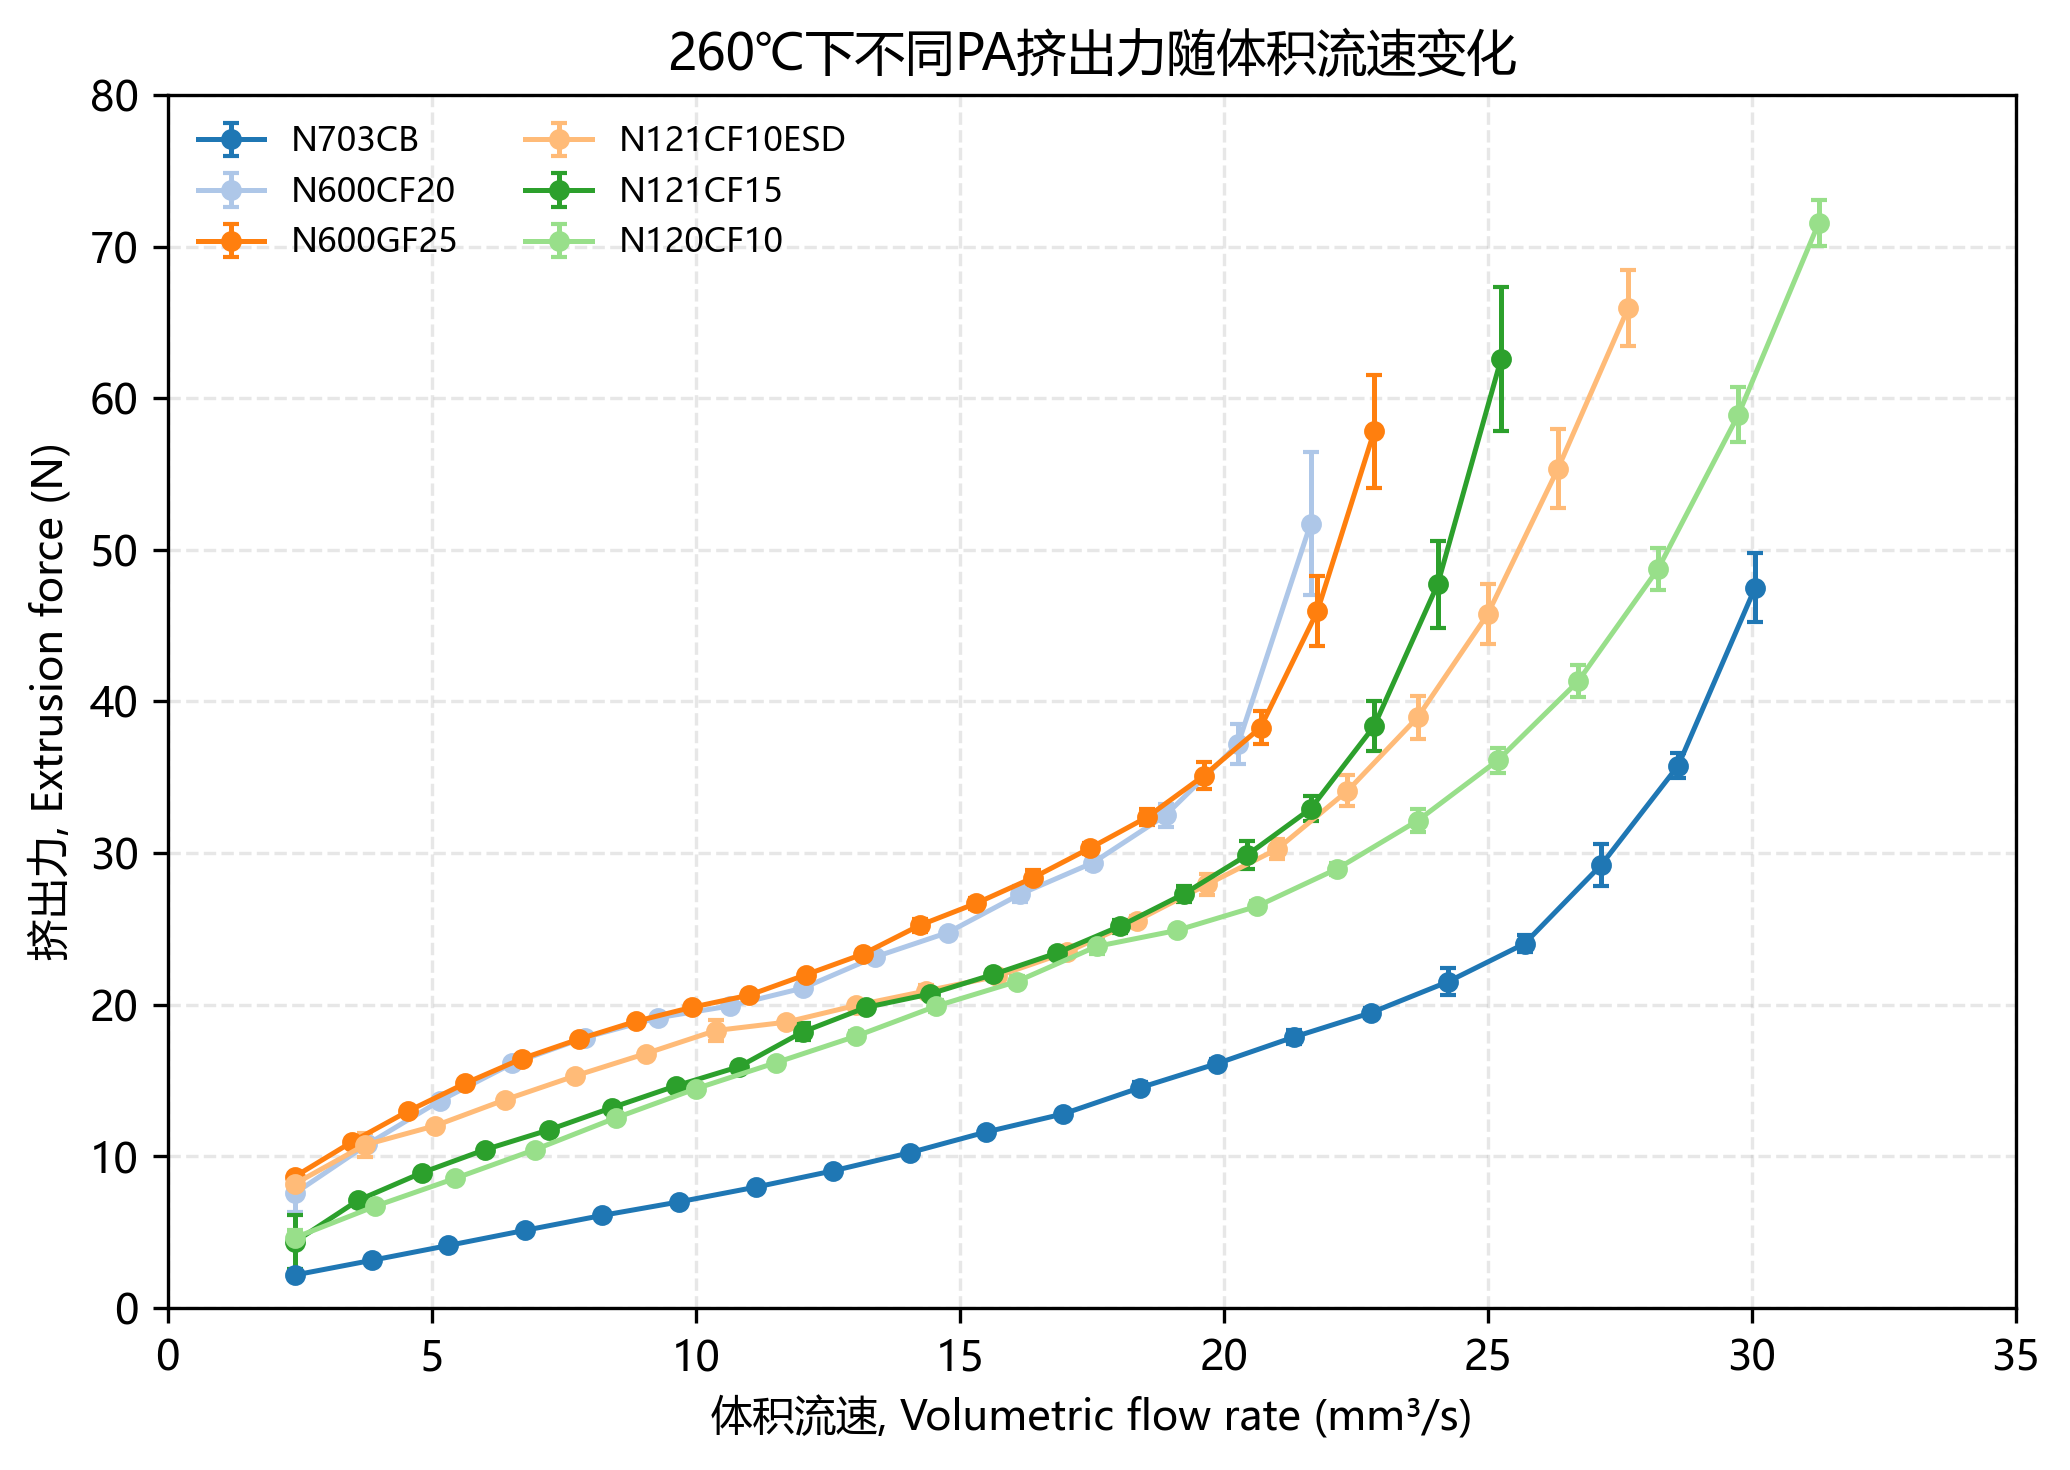

In [37]:
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
# =========================
# 数据
# =========================
datasets = {
    "N703CB": data1,
    "N600CF20": data2,
    "N600GF25": data3,
    "N121CF10ESD": data4,
    "N121CF15": data5,
    "N120CF10": data6
}

# =========================
# 作图
# =========================
fig, ax = plt.subplots(figsize=(7, 5), dpi=300)
ax.set_prop_cycle(color=plt.cm.tab20.colors)
for label, df in datasets.items():

    # 转换为数值
    feedrate = pd.to_numeric(df["feedrate_mms"], errors="coerce")
    force = pd.to_numeric(df["extrusion_force_N_mean"], errors="coerce")
    force_std = pd.to_numeric(df["extrusion_force_N_std"], errors="coerce")

    # 体积流速
    flow = feedrate * np.pi * 0.875**2

    # 去掉无效值
    valid = flow.notna() & force.notna() & force_std.notna()

    flow = flow[valid]
    force = force[valid]
    force_std = force_std[valid]

    # 按体积流速排序
    order = np.argsort(flow)
    flow = flow.iloc[order]
    force = force.iloc[order]
    force_std = force_std.iloc[order]

    # 曲线 + 数据点 + 标准差
    ax.errorbar(
        flow,
        force,
        yerr=force_std,
        fmt="o-",
        markersize=4,
        linewidth=1.2,
        capsize=2,
        label=label
    )


# =========================
# 图形设置
# =========================
ax.set_xlabel("体积流速, Volumetric flow rate (mm³/s)")
ax.set_ylabel("挤出力, Extrusion force (N)")
ax.set_title("260℃下不同PA挤出力随体积流速变化")

ax.set_xlim(0, 35)
ax.set_ylim(0, 80)

ax.grid(linestyle="--", alpha=0.3)
ax.legend(fontsize=8, frameon=False, ncol=2)

plt.tight_layout()
plt.show()

In [46]:
file_path1 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\E100CF17\20260810_094514_E100CF17-1 280℃_stats_clip3.0s.csv"
file_path2 = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\E120GF15\26.8.11 E120GF15复测\20260811_171932_E120GF15-2 280℃_stats_clip3.0s.csv"
data1 = pd.read_csv(file_path1)
data2 = pd.read_csv(file_path2)

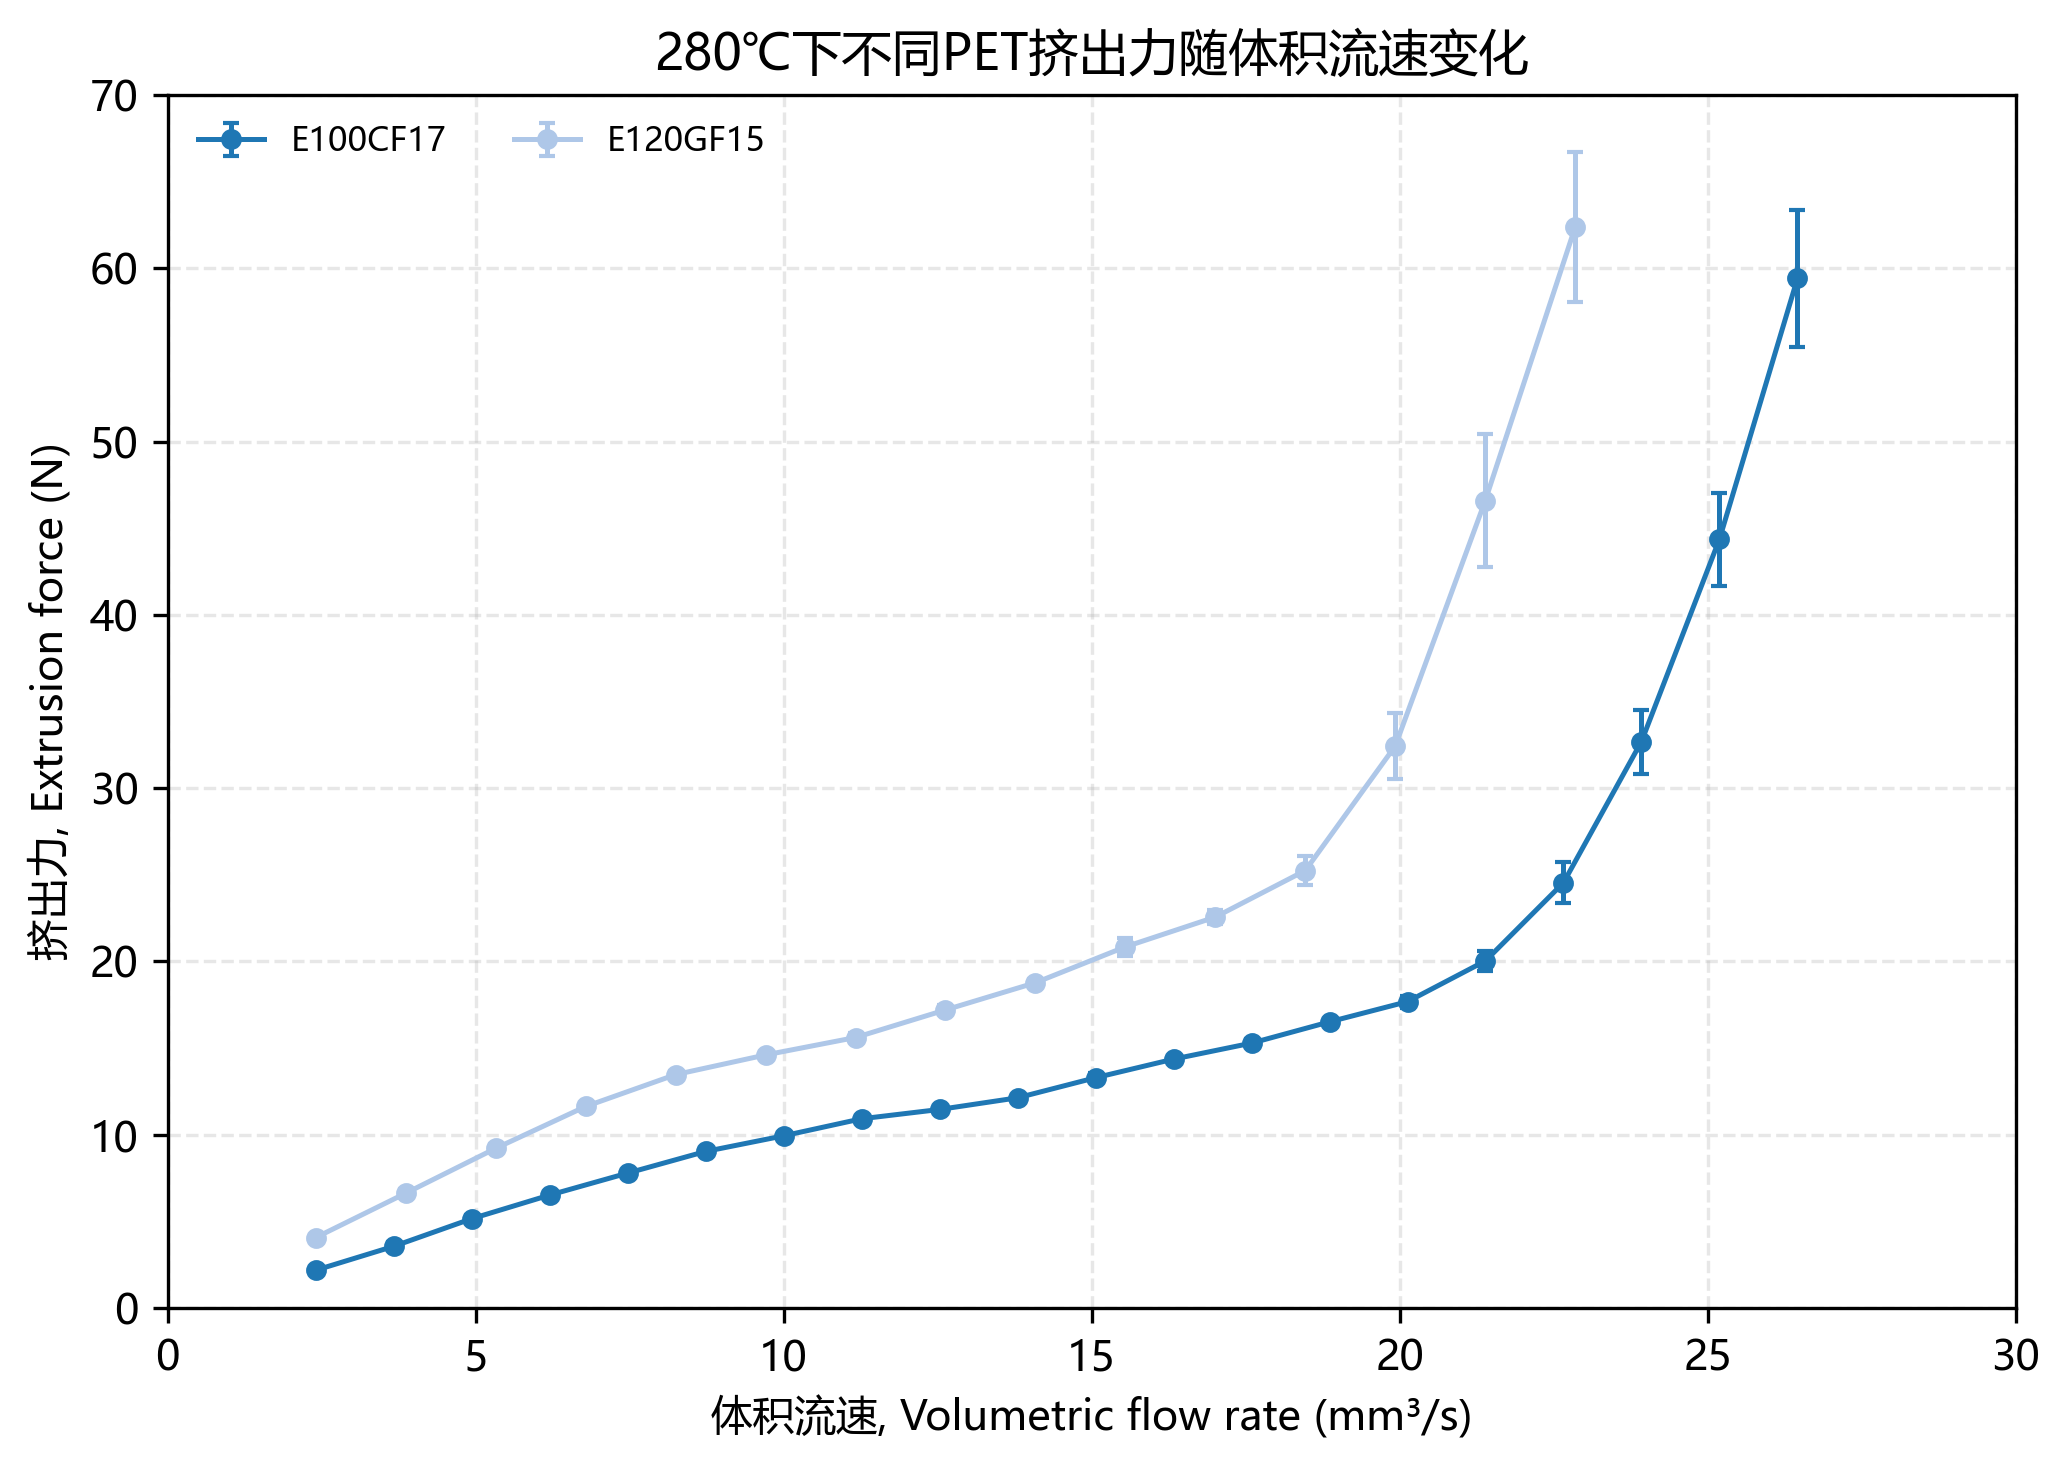

In [48]:
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
# =========================
# 数据
# =========================
datasets = {
    "E100CF17": data1,
    "E120GF15": data2
}
# =========================
# 作图
# =========================
fig, ax = plt.subplots(figsize=(7, 5), dpi=300)
ax.set_prop_cycle(color=plt.cm.tab20.colors)
for label, df in datasets.items():

    # 转换为数值
    feedrate = pd.to_numeric(df["feedrate_mms"], errors="coerce")
    force = pd.to_numeric(df["extrusion_force_N_mean"], errors="coerce")
    force_std = pd.to_numeric(df["extrusion_force_N_std"], errors="coerce")

    # 体积流速
    flow = feedrate * np.pi * 0.875**2

    # 去掉无效值
    valid = flow.notna() & force.notna() & force_std.notna()

    flow = flow[valid]
    force = force[valid]
    force_std = force_std[valid]

    # 按体积流速排序
    order = np.argsort(flow)
    flow = flow.iloc[order]
    force = force.iloc[order]
    force_std = force_std.iloc[order]

    # 曲线 + 数据点 + 标准差
    ax.errorbar(
        flow,
        force,
        yerr=force_std,
        fmt="o-",
        markersize=4,
        linewidth=1.2,
        capsize=2,
        label=label
    )


# =========================
# 图形设置
# =========================
ax.set_xlabel("体积流速, Volumetric flow rate (mm³/s)")
ax.set_ylabel("挤出力, Extrusion force (N)")
ax.set_title("280℃下不同PET挤出力随体积流速变化")

ax.set_xlim(0, 30)
ax.set_ylim(0, 70)

ax.grid(linestyle="--", alpha=0.3)
ax.legend(fontsize=8, frameon=False, ncol=2)

plt.tight_layout()
plt.show()

# 非稳态信息

L1002-27630 数据点数： 300
L1002-28518 数据点数： 300
L1002-25031 数据点数： 300
L1002-28497 数据点数： 300


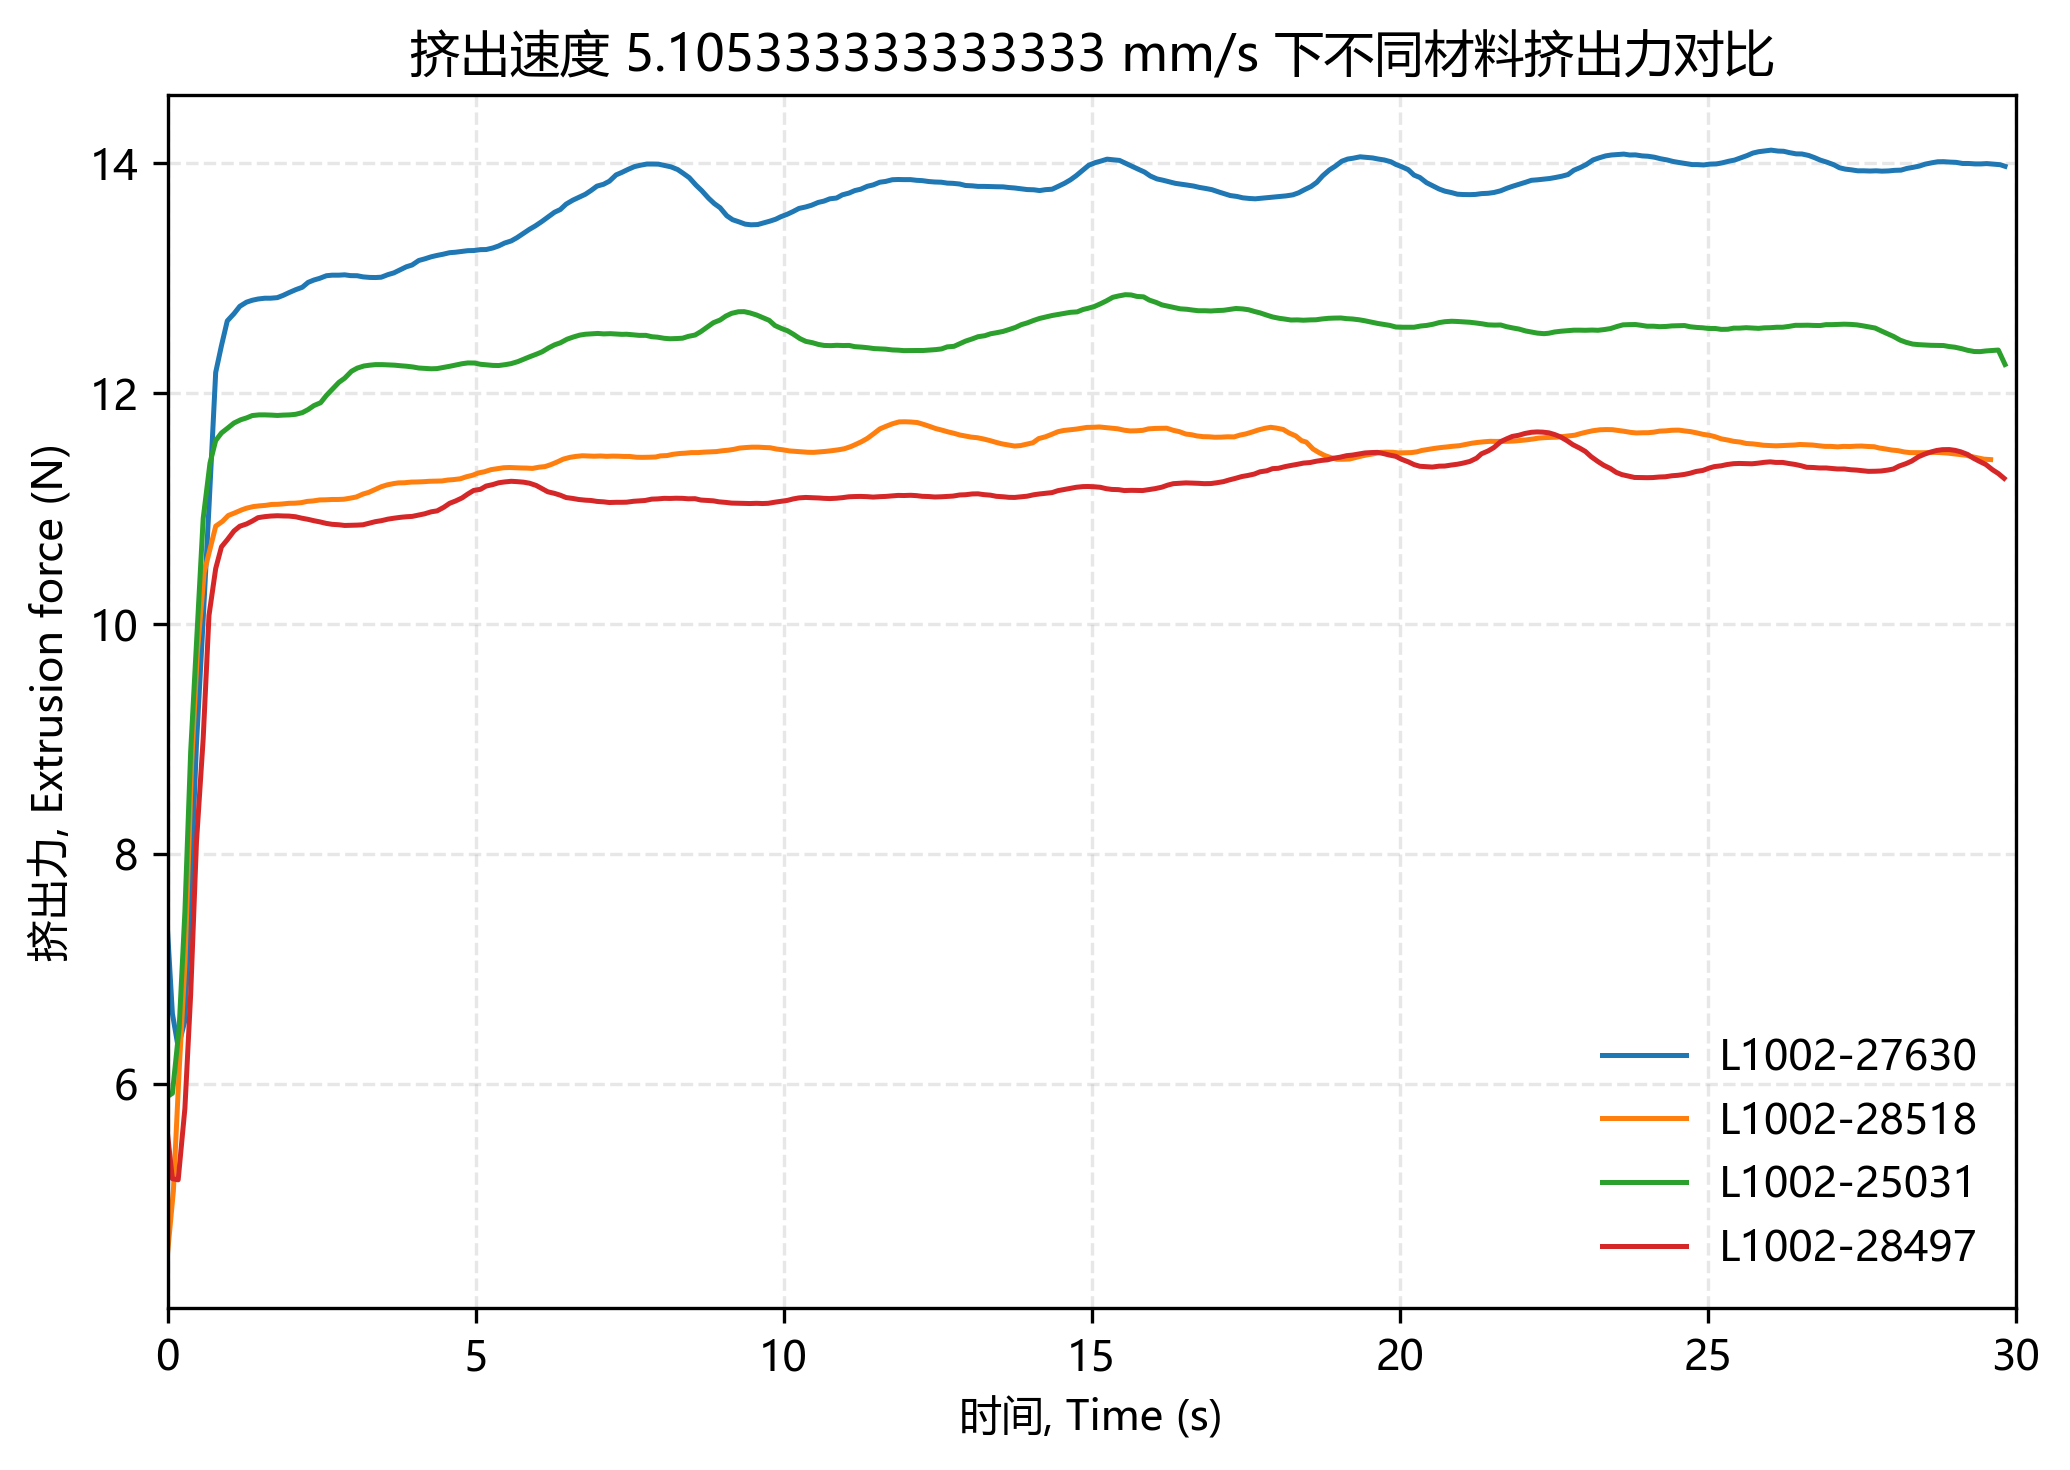

In [13]:
# =========================
# 1. 四种材料CSV
# =========================
files = {
    "L1002-27630": r"C:\Users\Administrator\Desktop\挤出平台\争议样品复测\26.7.2 L1002 F配方CCA210016不同单号挤出力测试数据\原始数据\20260702_101849_27630 220℃.csv",
    "L1002-28518": r"C:\Users\Administrator\Desktop\挤出平台\争议样品复测\26.7.2 L1002 F配方CCA210016不同单号挤出力测试数据\原始数据\20260702_103914_28518 220℃.csv",
    "L1002-25031": r"C:\Users\Administrator\Desktop\挤出平台\争议样品复测\26.7.2 L1002 F配方CCA210016不同单号挤出力测试数据\原始数据\20260702_110511_25031 220℃.csv",
    "L1002-28497": r"C:\Users\Administrator\Desktop\挤出平台\争议样品复测\26.7.2 L1002 F配方CCA210016不同单号挤出力测试数据\原始数据\20260702_131047_28497 220℃.csv",
}
target_speed = 5.105333333333333     # mm/s，在这里修改
tolerance = 0.05        # 允许 ±0.05 mm/s
duration = 30            # 取30秒数据
point_num = 300          # 最终保留300个点


# =========================
# 3. 作图
# =========================
fig, ax = plt.subplots(figsize=(7, 5), dpi=300)


for name, file in files.items():

    df = pd.read_csv(file)

    # A列：时间
    time = pd.to_numeric(df.iloc[:, 0], errors="coerce")

    # C列：挤出速度
    speed = pd.to_numeric(df.iloc[:, 2], errors="coerce")

    # H列：挤出力
    force = pd.to_numeric(df.iloc[:, 7], errors="coerce")


    # 找到目标速度的数据
    mask = abs(speed - target_speed) <= tolerance

    index = np.where(mask)[0]

    if len(index) == 0:
        print(name, "没有找到该速度的数据")
        continue


    # 找连续的数据段
    blocks = np.split(
        index,
        np.where(np.diff(index) != 1)[0] + 1
    )

    # 选择最长的连续段
    block = max(blocks, key=len)

    t = time.iloc[block].values
    f = force.iloc[block].values


    # 时间从0开始
    t = t - t[0]

    # 只取前30秒
    valid = t <= duration

    t = t[valid]
    f = f[valid]


    # 如果超过300点，均匀取300个点
    if len(t) > point_num:

        choose = np.linspace(
            0,
            len(t) - 1,
            point_num
        ).astype(int)

        t = t[choose]
        f = f[choose]


    # 绘制曲线
    ax.plot(
        t,
        f,
        linewidth=1.2,
        label=name
    )

    print(
        name,
        "数据点数：",
        len(f)
    )


# =========================
# 4. 图形设置
# =========================
ax.set_xlabel("时间, Time (s)")
ax.set_ylabel("挤出力, Extrusion force (N)")

ax.set_title(
    f"挤出速度 {target_speed} mm/s 下不同材料挤出力对比"
)

ax.set_xlim(0, 30)

ax.grid(
    linestyle="--",
    alpha=0.3
)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

检测到的速度：
[np.float64(0.26), np.float64(0.48), np.float64(0.51), np.float64(0.7), np.float64(1.0), np.float64(1.16), np.float64(1.6), np.float64(1.68), np.float64(1.69), np.float64(1.79), np.float64(2.37), np.float64(2.48), np.float64(2.52), np.float64(2.56), np.float64(2.83), np.float64(2.92), np.float64(3.05), np.float64(3.3), np.float64(3.38), np.float64(3.48), np.float64(3.51), np.float64(3.74), np.float64(4.42), np.float64(4.5), np.float64(4.51), np.float64(4.9), np.float64(5.0), np.float64(5.04), np.float64(5.11), np.float64(5.15), np.float64(5.53), np.float64(5.79), np.float64(5.98), np.float64(6.01), np.float64(6.1), np.float64(6.34), np.float64(6.47), np.float64(6.64), np.float64(7.16), np.float64(7.18), np.float64(7.84), np.float64(8.27), np.float64(8.53), np.float64(9.2), np.float64(9.21), np.float64(9.89), np.float64(9.97), np.float64(10.58), np.float64(11.16), np.float64(11.26), np.float64(11.95), np.float64(12.63), np.float64(12.64), np.float64(12.67), np.float64(13.32), np

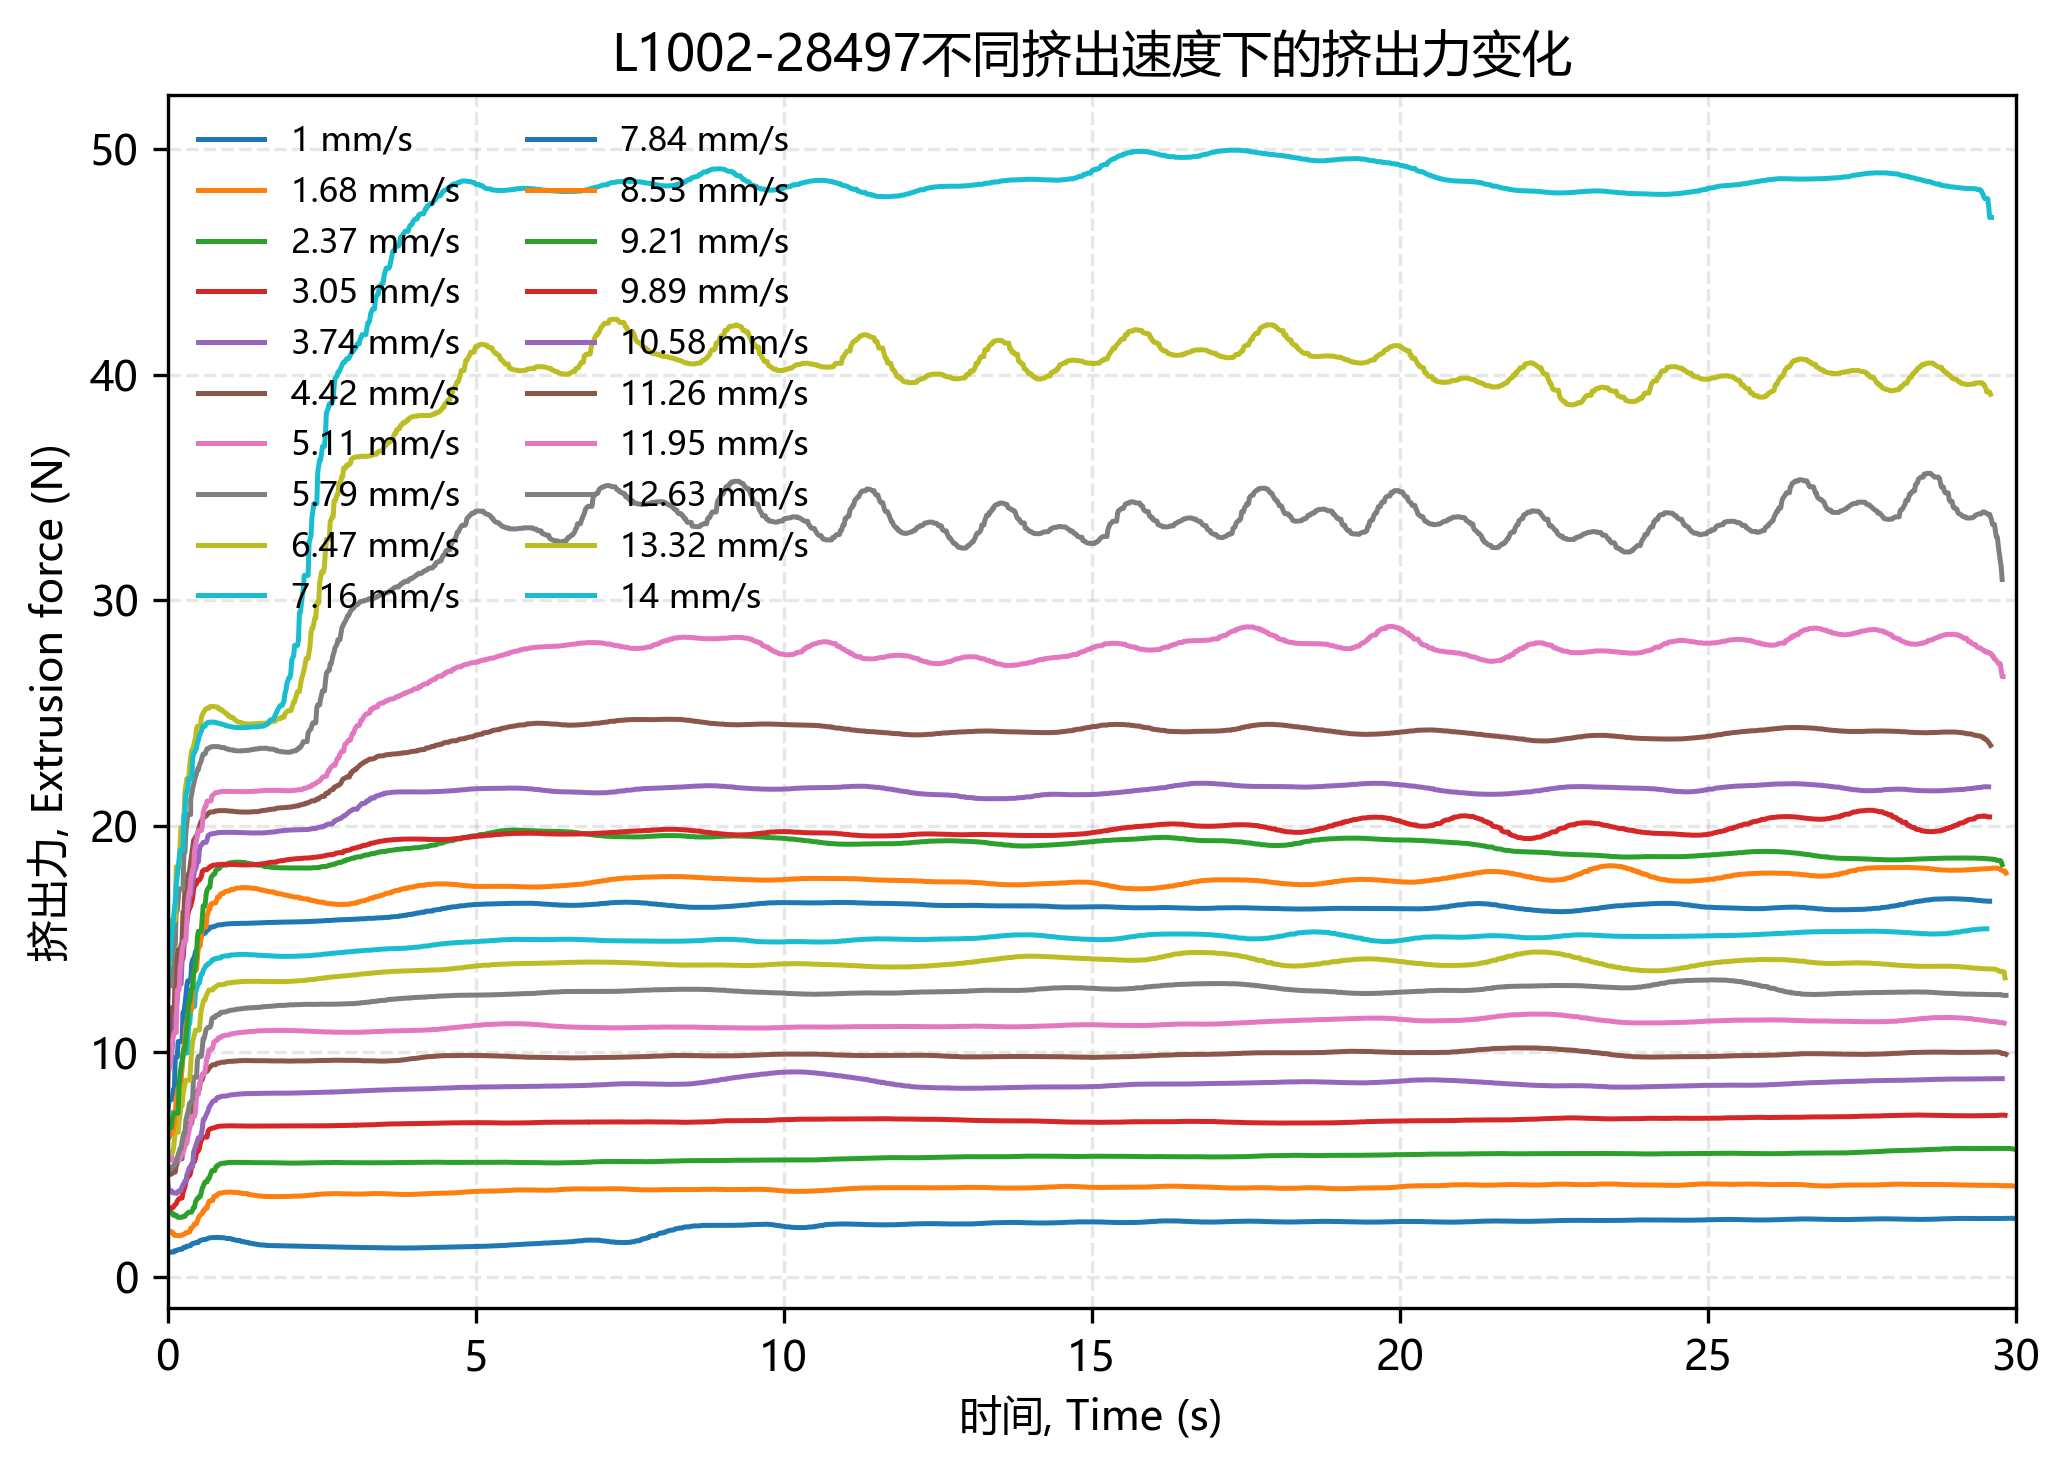

In [ ]:
file = r"C:\Users\Administrator\Desktop\挤出平台\争议样品复测\26.7.2 L1002 F配方CCA210016不同单号挤出力测试数据\原始数据\20260702_131047_28497 220℃.csv"
df = pd.read_csv(file)

# A列：时间
time = pd.to_numeric(df.iloc[:, 0], errors="coerce")

# C列：挤出速度
speed = pd.to_numeric(df.iloc[:, 2], errors="coerce")

# H列：挤出力
force = pd.to_numeric(df.iloc[:, 7], errors="coerce")


# =========================
# 2. 自动识别速度
# =========================

# 四舍五入，消除浮点误差
speed_round = speed.round(2)

# 找出所有不同速度
speeds = sorted(speed_round.dropna().unique())

# 去掉0速度
speeds = [s for s in speeds if s > 0]

print("检测到的速度：")
print(speeds)


# =========================
# 3. 作图
# =========================
fig, ax = plt.subplots(figsize=(7, 5), dpi=300)

for s in speeds:

    # 找到该速度的数据
    index = np.where(speed_round == s)[0]

    if len(index) == 0:
        continue

    # 分成连续的数据段
    blocks = np.split(
        index,
        np.where(np.diff(index) != 1)[0] + 1
    )

    # 取最长的一段
    block = max(blocks, key=len)

    t = time.iloc[block].values
    f = force.iloc[block].values

    # 时间从0开始
    t = t - t[0]

    # 只画30秒
    mask = t <= 30

    t = t[mask]
    f = f[mask]

    # 数据太少的不画
    if len(f) < 20:
        continue

    ax.plot(
        t,
        f,
        linewidth=1.2,
        label=f"{s:g} mm/s"
    )


# =========================
# 4. 图形设置
# =========================
ax.set_xlabel("时间, Time (s)")
ax.set_ylabel("挤出力, Extrusion force (N)")

ax.set_title("L1002-28497不同挤出速度下的挤出力变化")

ax.set_xlim(0, 30)


ax.grid(
    linestyle="--",
    alpha=0.3
)

ax.legend(
    fontsize=8,
    frameon=False,
    ncol=2
)

plt.tight_layout()
plt.show()

L1002 数据点数： 273
L1003 数据点数： 299
L1005 数据点数： 299
L1009 数据点数： 298
L2002 数据点数： 300
L3001 数据点数： 300
L1013 数据点数： 300
L4004 数据点数： 300
L4004GF12 数据点数： 300
L2002CF 数据点数： 300
L3003 数据点数： 300


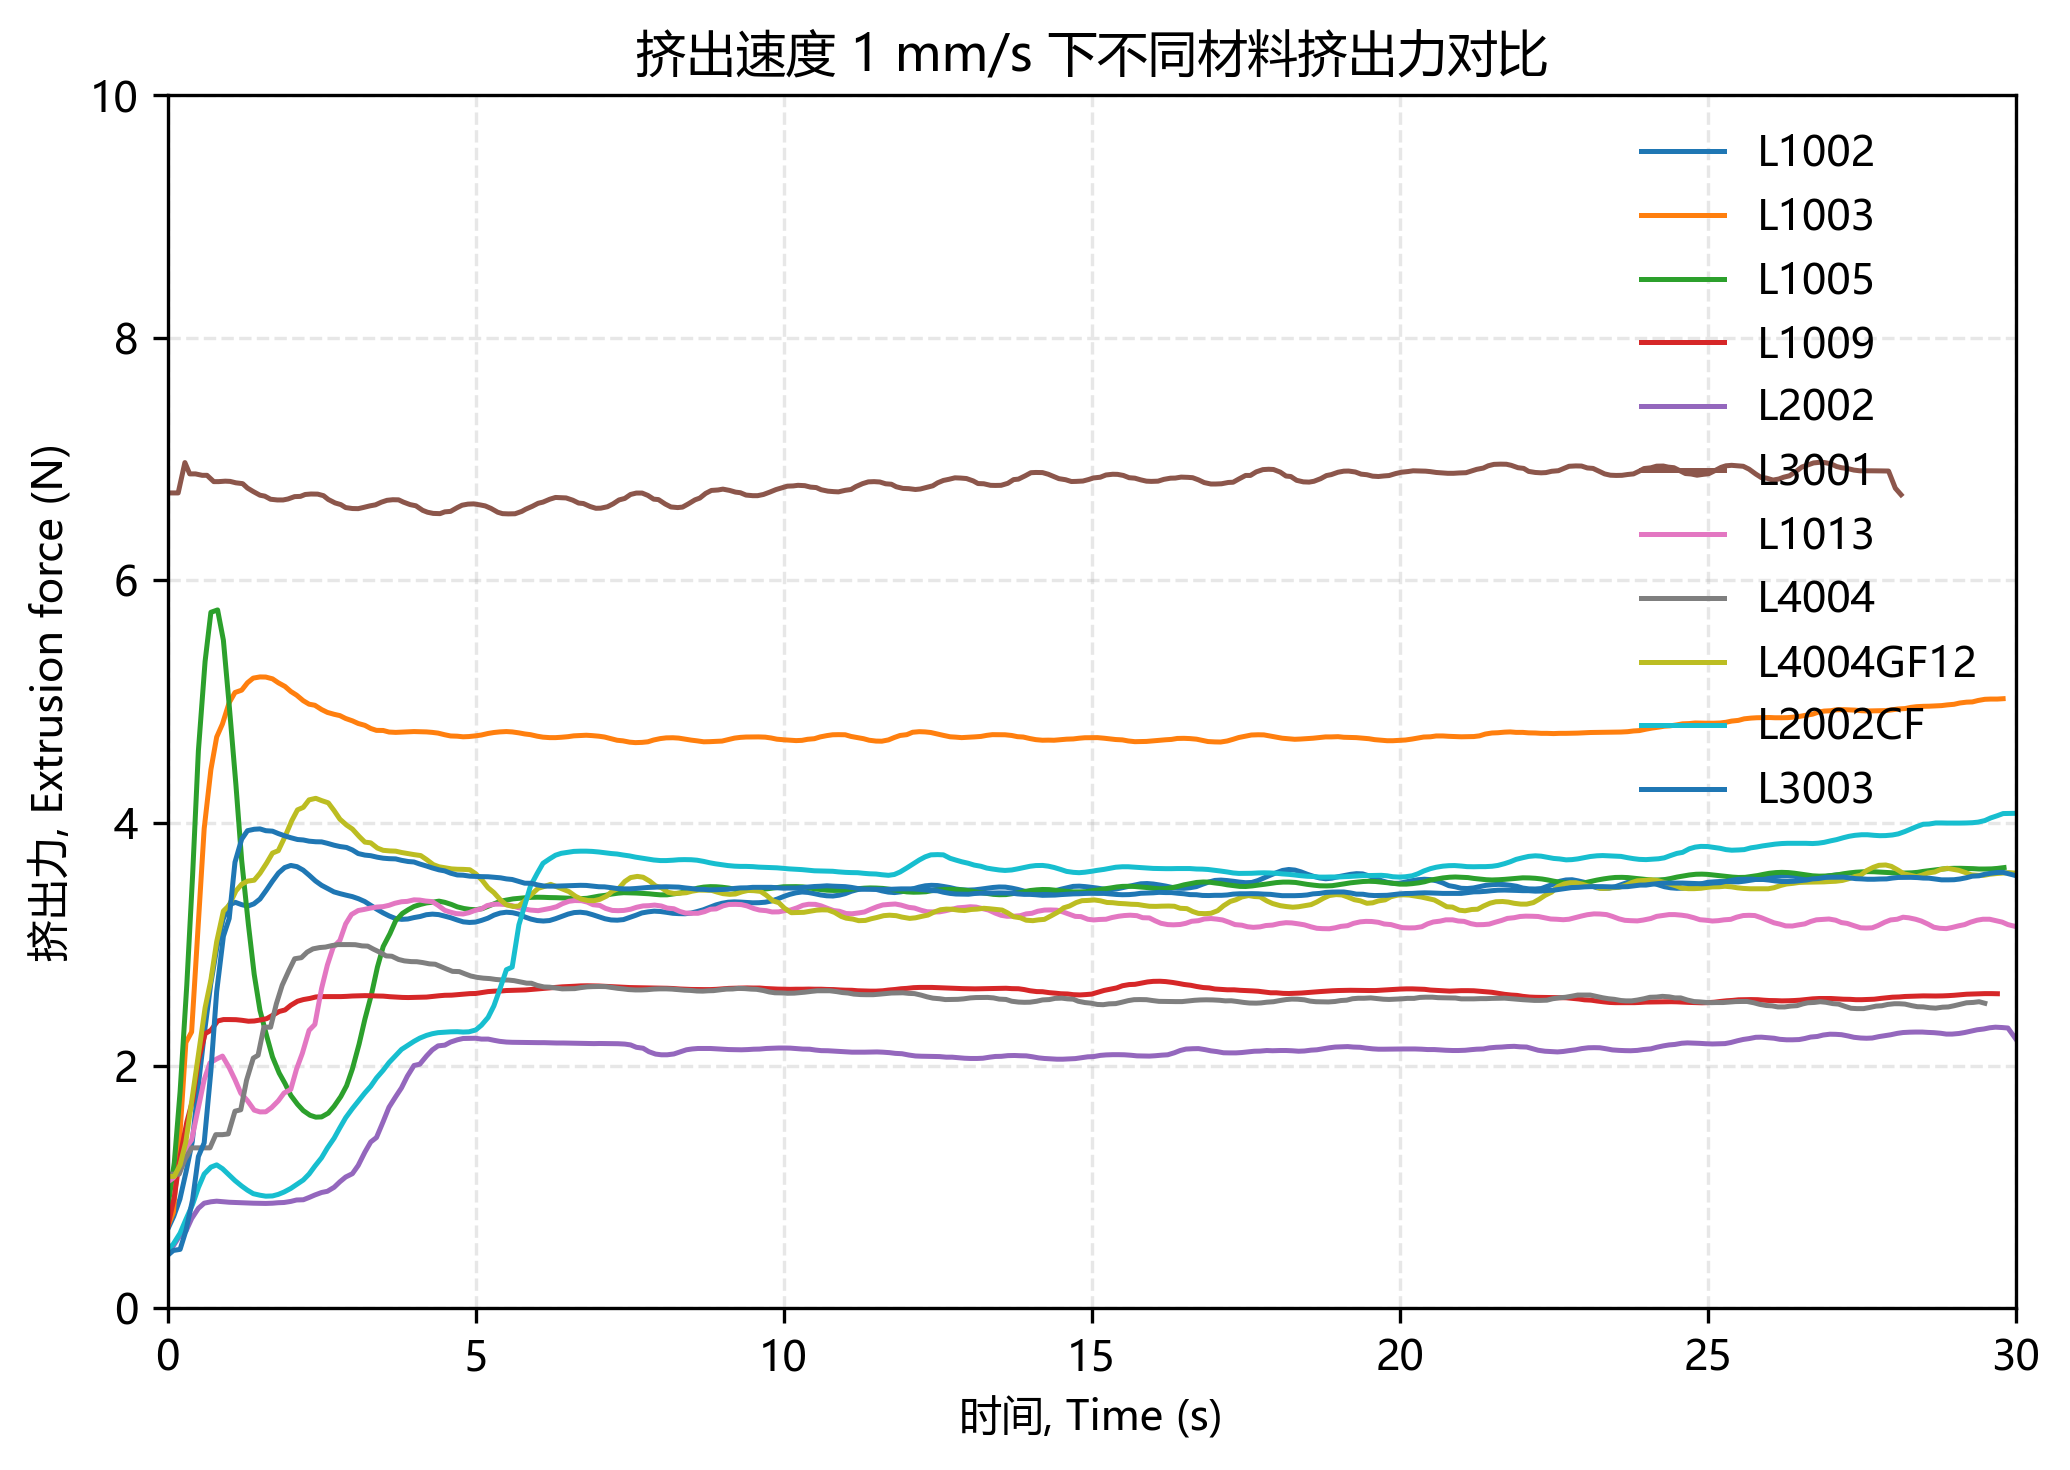

In [43]:
# 1. 四种材料CSV
# =========================
files = {
    "L1002": r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\L1002白色\26.6.15 L1002最新版本—设计自动开始或结束记录自动清零后\20260615_133726_L1002-2 220℃.csv",
    "L1003": r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\L1003\L1003\20260729_164451_L1003-2 220℃.csv",
    "L1005": r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\L1005\20260724_144749_L1005-1-220℃.csv",
    "L1009": r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\L1009\20260810_145857_L1009-1 220℃.csv",
    "L2002": r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\L2002 大理石白\20260717最新\20260717_151340_L2002黑220℃.csv",
    "L3001": r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\L3001\L3001 26.7.24\原始数据\20260724_094254_L3001-2 220℃.csv",
    "L1013": r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260720-L1013\20260720_155416_L1013-1-220℃.csv",
    "L4004": r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260722\20260722_090413_L4004-1-220℃.csv",
    "L4004GF12": r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260723\L4004GF12\20260723_164808_L4004GF12-2-220℃.csv",
    "L2002CF": r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260811\20260811_150626_L2002CF-2-220℃.csv",
    "L1005": r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260814\20260814_125502_L1005-2-220℃.csv",
    "L3003": r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\挤出力数据文件\20260817\20260818_092234_L3003-2-220℃.csv"
}
target_speed = 1     # mm/s，在这里修改
tolerance = 0.05        # 允许 ±0.05 mm/s
duration = 30            # 取30秒数据
point_num = 300          # 最终保留300个点


# =========================
# 3. 作图
# =========================
fig, ax = plt.subplots(figsize=(7, 5), dpi=300)


for name, file in files.items():

    df = pd.read_csv(file)

    # A列：时间
    time = pd.to_numeric(df.iloc[:, 0], errors="coerce")

    # C列：挤出速度
    speed = pd.to_numeric(df.iloc[:, 2], errors="coerce")

    # H列：挤出力
    force = pd.to_numeric(df.iloc[:, 7], errors="coerce")


    # 找到目标速度的数据
    mask = abs(speed - target_speed) <= tolerance

    index = np.where(mask)[0]

    if len(index) == 0:
        print(name, "没有找到该速度的数据")
        continue


    # 找连续的数据段
    blocks = np.split(
        index,
        np.where(np.diff(index) != 1)[0] + 1
    )

    # 选择最长的连续段
    block = max(blocks, key=len)

    t = time.iloc[block].values
    f = force.iloc[block].values


    # 时间从0开始
    t = t - t[0]

    # 只取前30秒
    valid = t <= duration

    t = t[valid]
    f = f[valid]


    # 如果超过300点，均匀取300个点
    if len(t) > point_num:

        choose = np.linspace(
            0,
            len(t) - 1,
            point_num
        ).astype(int)

        t = t[choose]
        f = f[choose]


    # 绘制曲线
    ax.plot(
        t,
        f,
        linewidth=1.2,
        label=name
    )

    print(
        name,
        "数据点数：",
        len(f)
    )

ax.set_prop_cycle(color=plt.cm.tab20.colors)
# =========================
# 4. 图形设置
# =========================
ax.set_xlabel("时间, Time (s)")
ax.set_ylabel("挤出力, Extrusion force (N)")

ax.set_title(
    f"挤出速度 {target_speed} mm/s 下不同材料挤出力对比"
)

ax.set_xlim(0, 30)
ax.set_ylim(0, 10)

ax.grid(
    linestyle="--",
    alpha=0.3
)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

检测到温度： [np.float64(190.0), np.float64(202.5), np.float64(215.0), np.float64(227.5), np.float64(240.0)]
190℃：273个数据点，持续时间 27.2s
202.5℃：272个数据点，持续时间 27.1s
215℃：273个数据点，持续时间 27.2s
227.5℃：273个数据点，持续时间 27.2s
240℃：273个数据点，持续时间 27.2s


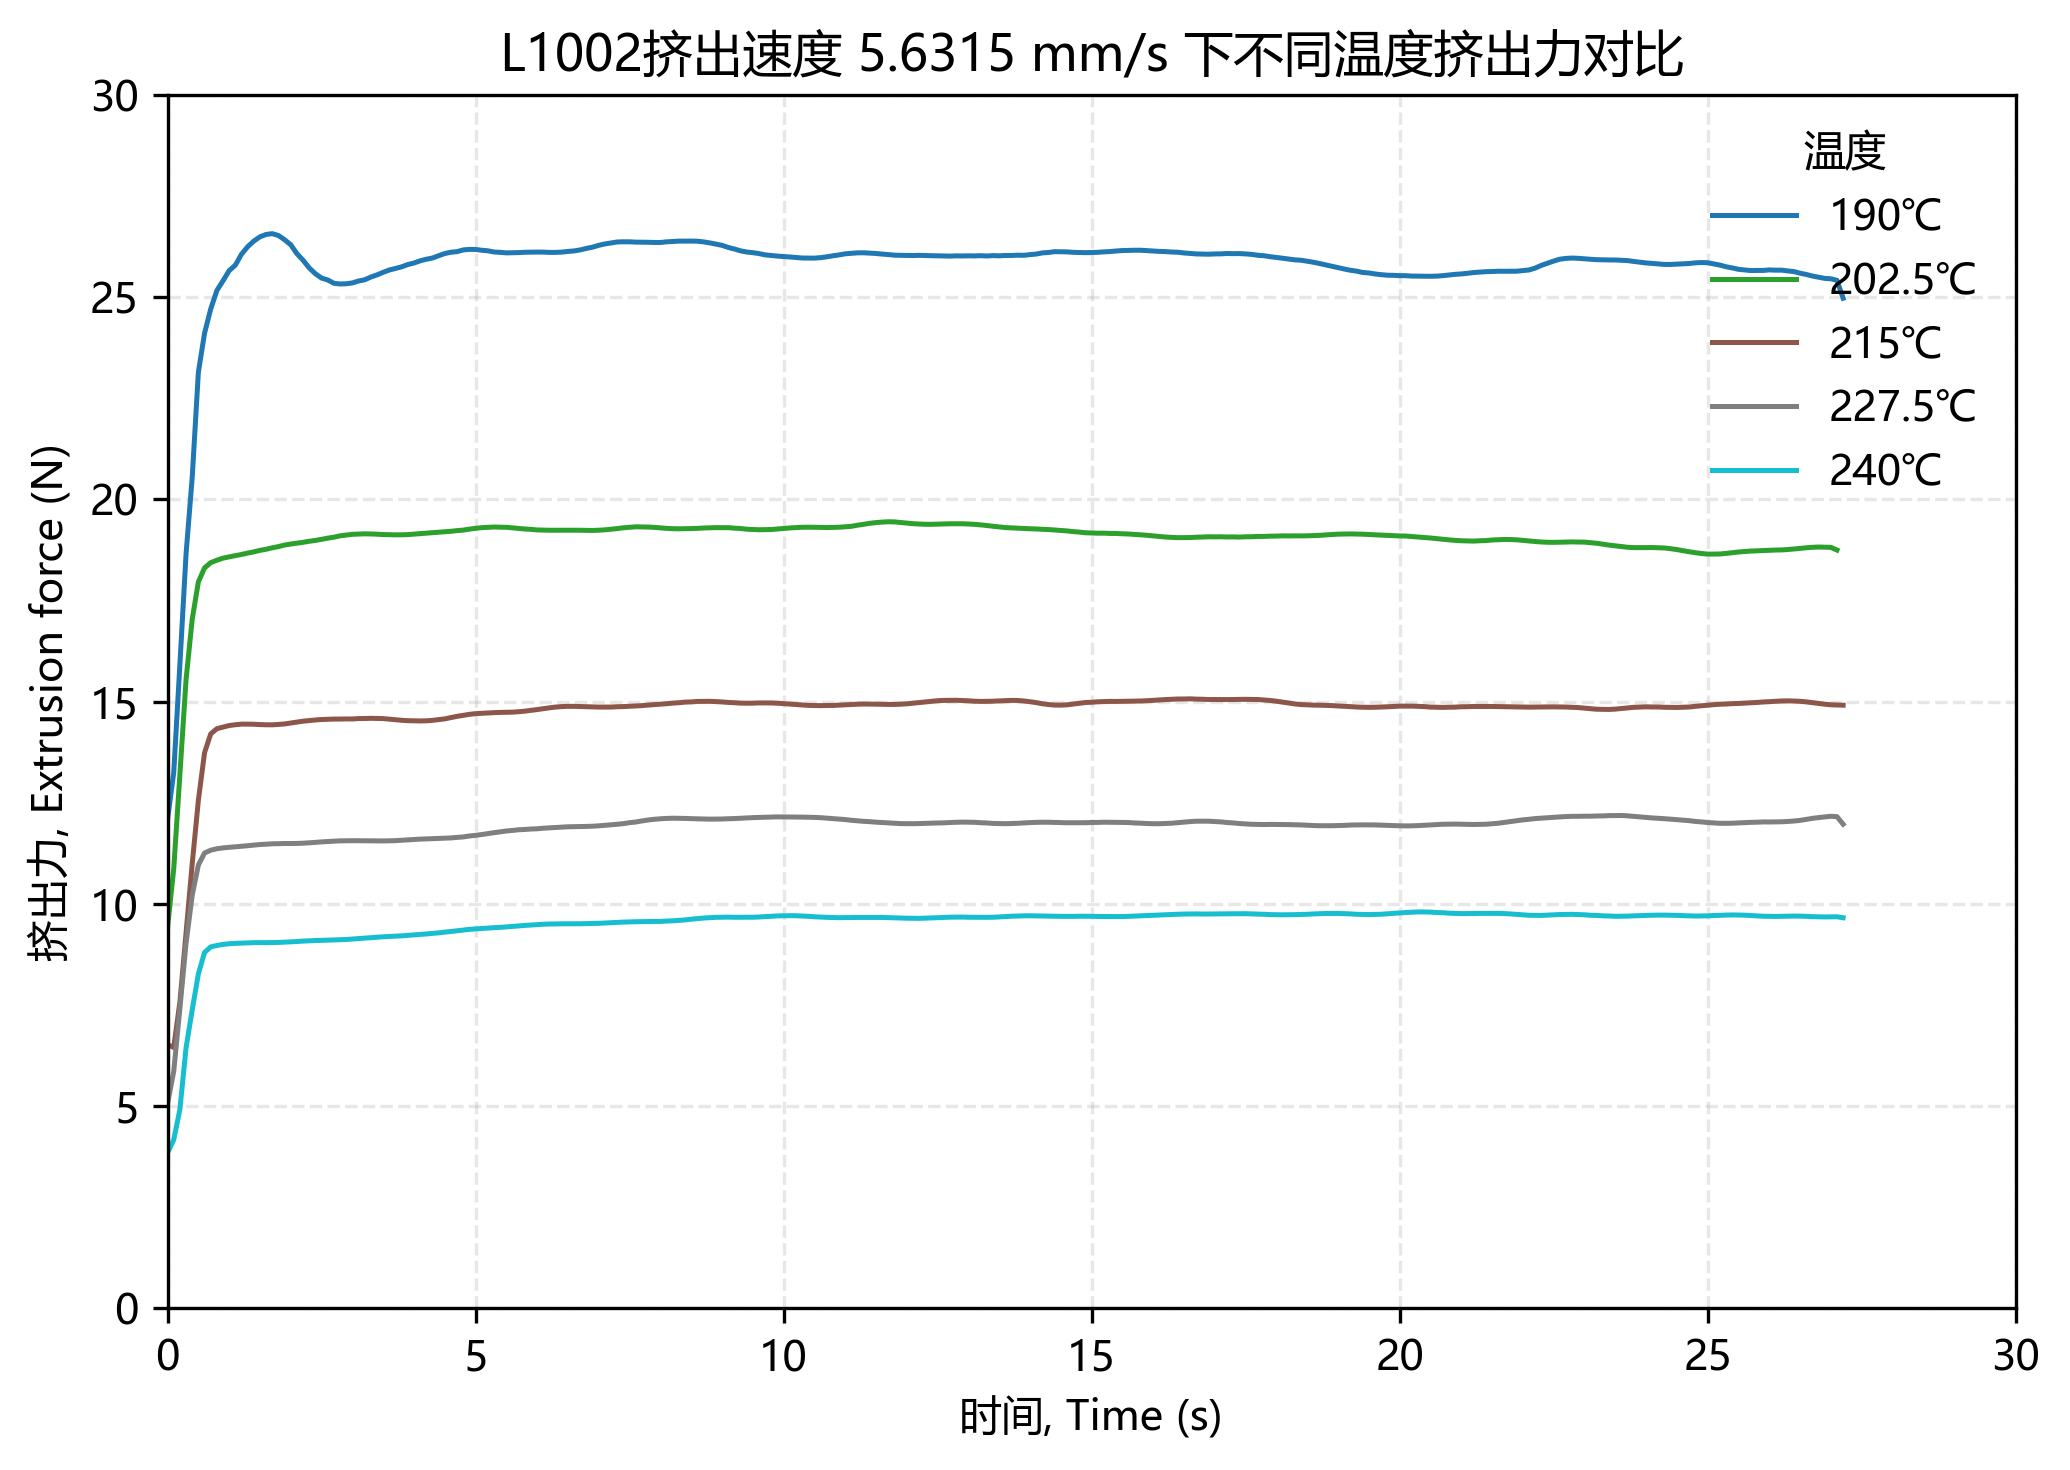

In [36]:
file_path = r"C:\Users\Administrator\Desktop\挤出平台\PI Code测试\L1002白色\L1002 白色\L1002-1 1.26.csv"

df = pd.read_csv(file_path)

time = pd.to_numeric(df["time_s"], errors="coerce")
temp = pd.to_numeric(df["temperature_C"], errors="coerce")
speed = pd.to_numeric(df["feedrate_mms"], errors="coerce")
force = pd.to_numeric(df["extrusion_force_N"], errors="coerce")


# =========================
# 2. 指定比较速度
# =========================
target_speed = 5.6315      # mm/s，在这里修改
tolerance = 0.02         # 速度允许误差


# 自动获取所有温度
temperatures = sorted(temp.dropna().unique())

print("检测到温度：", temperatures)


# =========================
# 3. 绘图
# =========================
fig, ax = plt.subplots(figsize=(7, 5), dpi=300)

colors = plt.cm.tab10(np.linspace(0, 1, len(temperatures)))


for i, T in enumerate(temperatures):

    # 同时满足：指定温度 + 指定速度
    mask = (
        (temp == T) &
        (abs(speed - target_speed) <= tolerance)
    )

    index = np.where(mask)[0]

    if len(index) == 0:
        print(f"{T}℃：没有找到 {target_speed} mm/s 数据")
        continue

    # 分割连续数据段
    blocks = np.split(
        index,
        np.where(np.diff(index) != 1)[0] + 1
    )

    # 取最长的连续稳定段
    block = max(blocks, key=len)

    t = time.iloc[block].values
    f = force.iloc[block].values

    # 每条曲线时间都从0开始
    t = t - t[0]

    ax.plot(
        t,
        f,
        color=colors[i],
        linewidth=1.2,
        label=f"{T:g}℃"
    )

    print(
        f"{T:g}℃：{len(f)}个数据点，"
        f"持续时间 {t[-1]:.1f}s"
    )


# =========================
# 4. 图形设置
# =========================
ax.set_xlabel("时间, Time (s)")
ax.set_ylabel("挤出力, Extrusion force (N)")

ax.set_title(
    f"L1002挤出速度 {target_speed} mm/s 下不同温度挤出力对比"
)

ax.grid(
    linestyle="--",
    alpha=0.3
)

ax.legend(
    title="温度",
    frameon=False
)
ax.set_xlim(0, 30)
ax.set_ylim(0, 30)
plt.tight_layout()
plt.show()